# Recomendação de Culturas Agrícolas com Machine Learning

Trabalho II de Machine Learning. A partir de 7 medidas de solo e clima (N, P, K, temperatura, umidade, pH e chuva), queremos recomendar a cultura mais adequada para uma área.

- **Modelos:** SVM, Árvore de Decisão, Random Forest, XGBoost e K-means
- **Dataset:** [Crop Recommendation Dataset (Kaggle)](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset)

## 0. Bibliotecas e configurações

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import xgboost

RANDOM_STATE = 42
CAMINHO_DATASET = "dataset.csv"
PASTA_FIGURAS = "Figuras"
PASTA_RESULTADOS = "Resultados"
COR_PRINCIPAL = "#2e7d32"
os.makedirs(PASTA_FIGURAS, exist_ok=True)
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

print("Python", sys.version.split()[0])
for biblioteca in [np, pd, matplotlib, sklearn, xgboost]:
    print(biblioteca.__name__, biblioteca.__version__)

Python 3.12.3
numpy 2.5.4
pandas 3.1.0
matplotlib 3.11.2
sklearn 1.8.0
xgboost 3.4.1


## 1. Carregamento e inspeção dos dados

In [2]:
COLUNAS_ATRIBUTOS = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
COLUNA_ALVO = "label"

# nomes em português para tabelas e gráficos
NOMES_ATRIBUTOS = {
    "N": "Nitrogênio (N)",
    "P": "Fósforo (P)",
    "K": "Potássio (K)",
    "temperature": "Temperatura (°C)",
    "humidity": "Umidade (%)",
    "ph": "pH do solo",
    "rainfall": "Chuva (mm)",
}
NOMES_CULTURAS = {
    "apple": "maçã", "banana": "banana", "blackgram": "feijão-preto (urad)",
    "chickpea": "grão-de-bico", "coconut": "coco", "coffee": "café",
    "cotton": "algodão", "grapes": "uva", "jute": "juta",
    "kidneybeans": "feijão-roxo", "lentil": "lentilha", "maize": "milho",
    "mango": "manga", "mothbeans": "feijão-mariposa", "mungbean": "feijão-mungo",
    "muskmelon": "melão", "orange": "laranja", "papaya": "mamão",
    "pigeonpeas": "feijão-guandu", "pomegranate": "romã", "rice": "arroz",
    "watermelon": "melancia",
}

dados = pd.read_csv(CAMINHO_DATASET)
dados.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
print("Linhas:", dados.shape[0], "| colunas:", dados.shape[1])
print(dados.dtypes.to_string())
print("\nValores ausentes:", int(dados.isna().sum().sum()))
print("Linhas duplicadas:", int(dados.duplicated().sum()))

contagem_classes = dados[COLUNA_ALVO].value_counts()
print("\nCulturas:", dados[COLUNA_ALVO].nunique())
print("Amostras por cultura: de", contagem_classes.min(), "a", contagem_classes.max())

Linhas: 2200 | colunas: 8
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str

Valores ausentes: 0
Linhas duplicadas: 0

Culturas: 22
Amostras por cultura: de 100 a 100


Não há valores ausentes nem linhas duplicadas, e as 22 culturas têm 100 amostras cada (classes balanceadas).

## 2. Análise exploratória (EDA)

In [4]:
def salvar_figura(figura, nome_arquivo):
    caminho = os.path.join(PASTA_FIGURAS, nome_arquivo)
    figura.savefig(caminho, dpi=150, bbox_inches="tight")
    print("Figura salva em:", caminho)


def criar_grade_atributos(titulo):
    # 7 variáveis em uma grade 2 x 4 (a última posição fica vazia)
    figura, eixos = plt.subplots(2, 4, figsize=(16, 7))
    eixos = eixos.flatten()
    eixos[-1].axis("off")
    figura.suptitle(titulo, fontsize=14)
    return figura, eixos


def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


estatisticas = dados[COLUNAS_ATRIBUTOS].describe().T.round(2)
estatisticas.index = [NOMES_ATRIBUTOS[c] for c in estatisticas.index]
estatisticas

,count,mean,std,min,25%,50%,75%,max
Nitrogênio (N),2200.0,50.55,36.92,0.00,21.00,37.00,84.25,140.00
Fósforo (P),2200.0,53.36,32.99,5.00,28.00,51.00,68.00,145.00
Potássio (K),2200.0,48.15,50.65,5.00,20.00,32.00,49.00,205.00
Temperatura (°C),2200.0,25.62,5.06,8.83,22.77,25.60,28.56,43.68
Umidade (%),2200.0,71.48,22.26,14.26,60.26,80.47,89.95,99.98
pH do solo,2200.0,6.47,0.77,3.50,5.97,6.43,6.92,9.94
Chuva (mm),2200.0,103.46,54.96,20.21,64.55,94.87,124.27,298.56


Figura salva em: Figuras\eda_histogramas.png


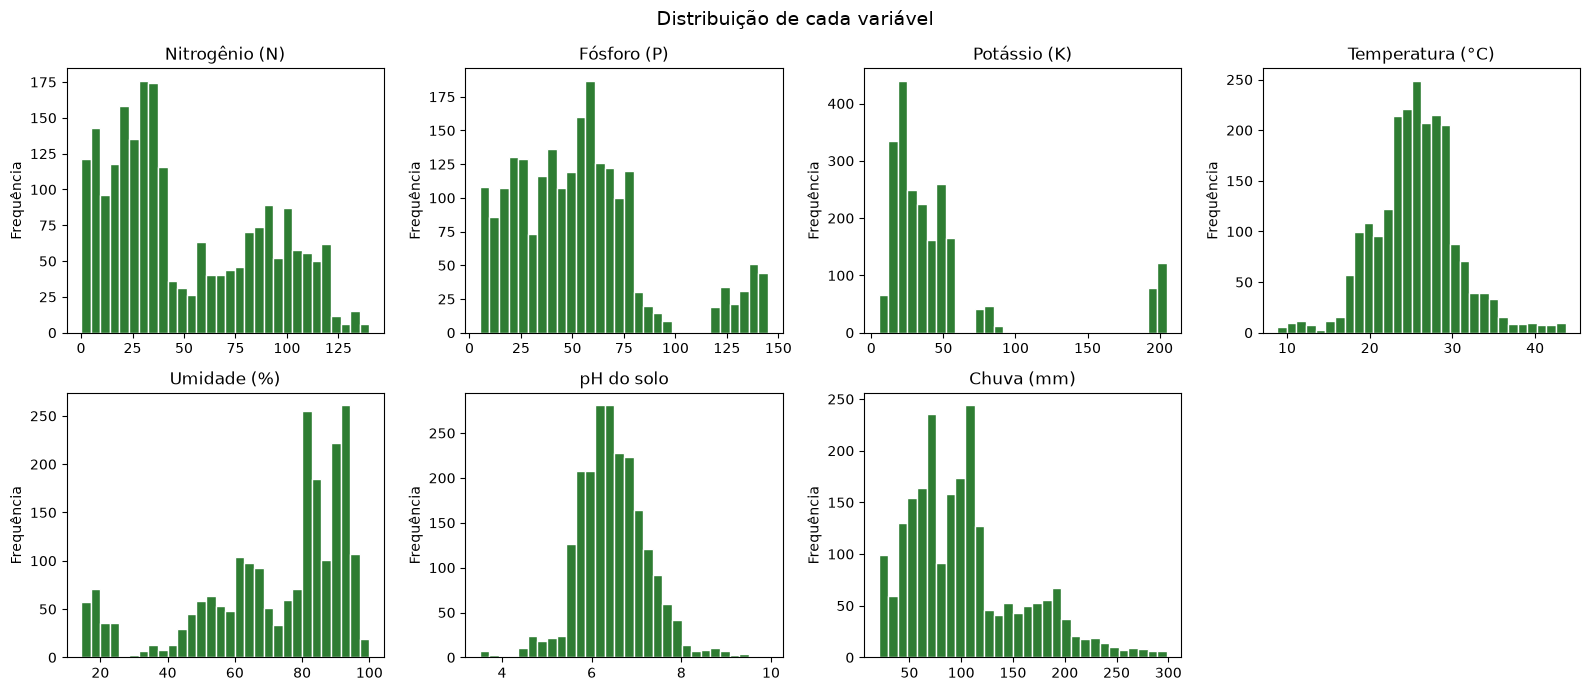

In [5]:
figura, eixos = criar_grade_atributos("Distribuição de cada variável")
for eixo, coluna in zip(eixos, COLUNAS_ATRIBUTOS):
    eixo.hist(dados[coluna], bins=30, color=COR_PRINCIPAL, edgecolor="white")
    eixo.set_title(NOMES_ATRIBUTOS[coluna])
    eixo.set_ylabel("Frequência")
figura.tight_layout()
salvar_figura(figura, "eda_histogramas.png")
plt.show()

Figura salva em: Figuras\eda_boxplots.png


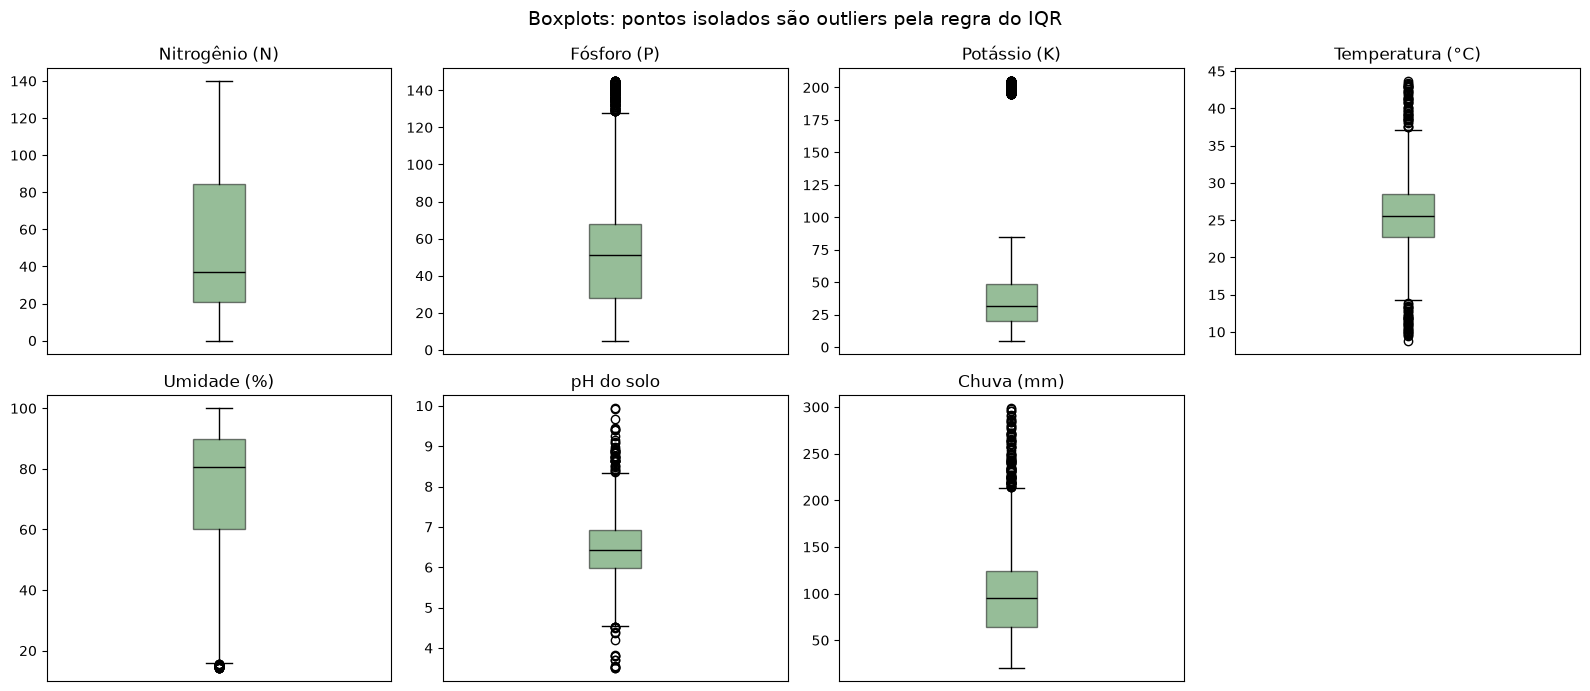

Total de outliers: 611 | linhas com pelo menos um: 432 (19.6%)


,Variável,Limite inferior,Limite superior,Outliers,Principais culturas
0,Nitrogênio (N),-73.88,179.12,0,-
1,Fósforo (P),-32.00,128.00,138,"maçã (70), uva (68)"
2,Potássio (K),-23.50,92.50,200,"uva (100), maçã (100)"
3,Temperatura (°C),14.08,37.25,86,"mamão (35), uva (34), laranja (17)"
4,Umidade (%),15.73,134.48,30,grão-de-bico (30)
5,pH do solo,4.54,8.35,57,"feijão-mariposa (42), grão-de-bico (13), manga..."
6,Chuva (mm),-25.02,213.84,100,"arroz (68), mamão (17), coco (15)"


In [6]:
figura, eixos = criar_grade_atributos("Boxplots: pontos isolados são outliers pela regra do IQR")
for eixo, coluna in zip(eixos, COLUNAS_ATRIBUTOS):
    eixo.boxplot(dados[coluna], patch_artist=True,
                 boxprops={"facecolor": COR_PRINCIPAL, "alpha": 0.5},
                 medianprops={"color": "black"})
    eixo.set_title(NOMES_ATRIBUTOS[coluna])
    eixo.set_xticks([])
figura.tight_layout()
salvar_figura(figura, "eda_boxplots.png")
plt.show()

linhas_outliers = []
tem_outlier = pd.Series(False, index=dados.index)
for coluna in COLUNAS_ATRIBUTOS:
    limite_inferior, limite_superior = limites_iqr(dados[coluna])
    eh_outlier = (dados[coluna] < limite_inferior) | (dados[coluna] > limite_superior)
    tem_outlier |= eh_outlier
    culturas = dados.loc[eh_outlier, COLUNA_ALVO].value_counts().head(3)
    linhas_outliers.append({
        "Variável": NOMES_ATRIBUTOS[coluna],
        "Limite inferior": round(limite_inferior, 2),
        "Limite superior": round(limite_superior, 2),
        "Outliers": int(eh_outlier.sum()),
        "Principais culturas": ", ".join(f"{NOMES_CULTURAS[c]} ({n})" for c, n in culturas.items()) or "-",
    })

tabela_outliers = pd.DataFrame(linhas_outliers)
print("Total de outliers:", tabela_outliers["Outliers"].sum(),
      f"| linhas com pelo menos um: {tem_outlier.sum()} ({tem_outlier.mean():.1%})")
tabela_outliers

Os outliers se concentram em poucas culturas (todo o potássio muito alto é de uva e maçã, e toda a umidade muito baixa é do grão-de-bico). São características dessas culturas e não erros, então foram mantidos.

Figura salva em: Figuras\eda_correlacao.png


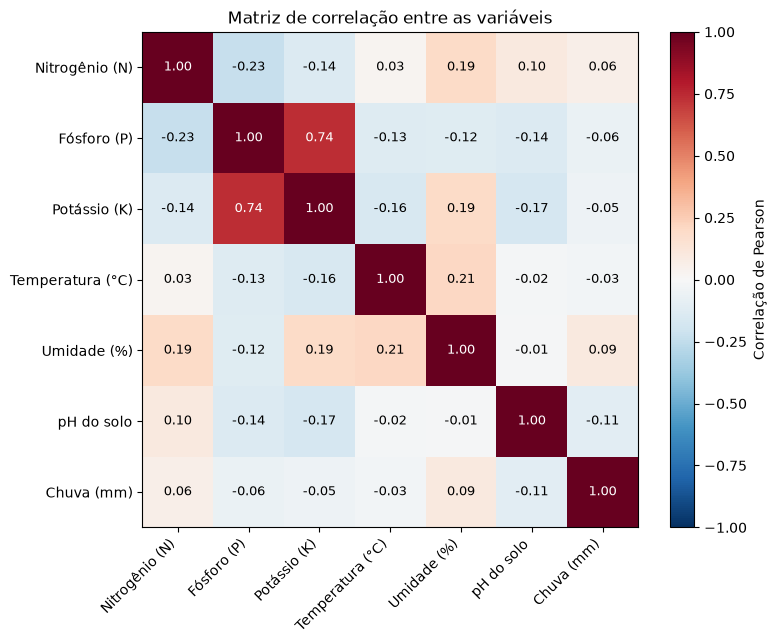

Maior correlação: P x K = 0.74


In [7]:
correlacao = dados[COLUNAS_ATRIBUTOS].corr()
rotulos = [NOMES_ATRIBUTOS[c] for c in COLUNAS_ATRIBUTOS]

figura, eixo = plt.subplots(figsize=(8, 6.5))
imagem = eixo.imshow(correlacao, cmap="RdBu_r", vmin=-1, vmax=1)
eixo.set_xticks(range(len(rotulos)), rotulos, rotation=45, ha="right")
eixo.set_yticks(range(len(rotulos)), rotulos)
for i in range(len(rotulos)):
    for j in range(len(rotulos)):
        valor = correlacao.iloc[i, j]
        eixo.text(j, i, f"{valor:.2f}", ha="center", va="center",
                  color="white" if abs(valor) > 0.6 else "black", fontsize=9)
figura.colorbar(imagem, ax=eixo, label="Correlação de Pearson")
eixo.set_title("Matriz de correlação entre as variáveis")
figura.tight_layout()
salvar_figura(figura, "eda_correlacao.png")
plt.show()

pares = correlacao.where(~np.eye(len(correlacao), dtype=bool)).abs().stack()
par_mais_forte = pares.idxmax()
print(f"Maior correlação: {par_mais_forte[0]} x {par_mais_forte[1]} = {correlacao.loc[par_mais_forte]:.2f}")

P e K têm correlação de 0,74, mas as duas foram mantidas: é o potássio que separa uva e maçã das outras culturas.

Figura salva em: Figuras\eda_perfil_culturas.png


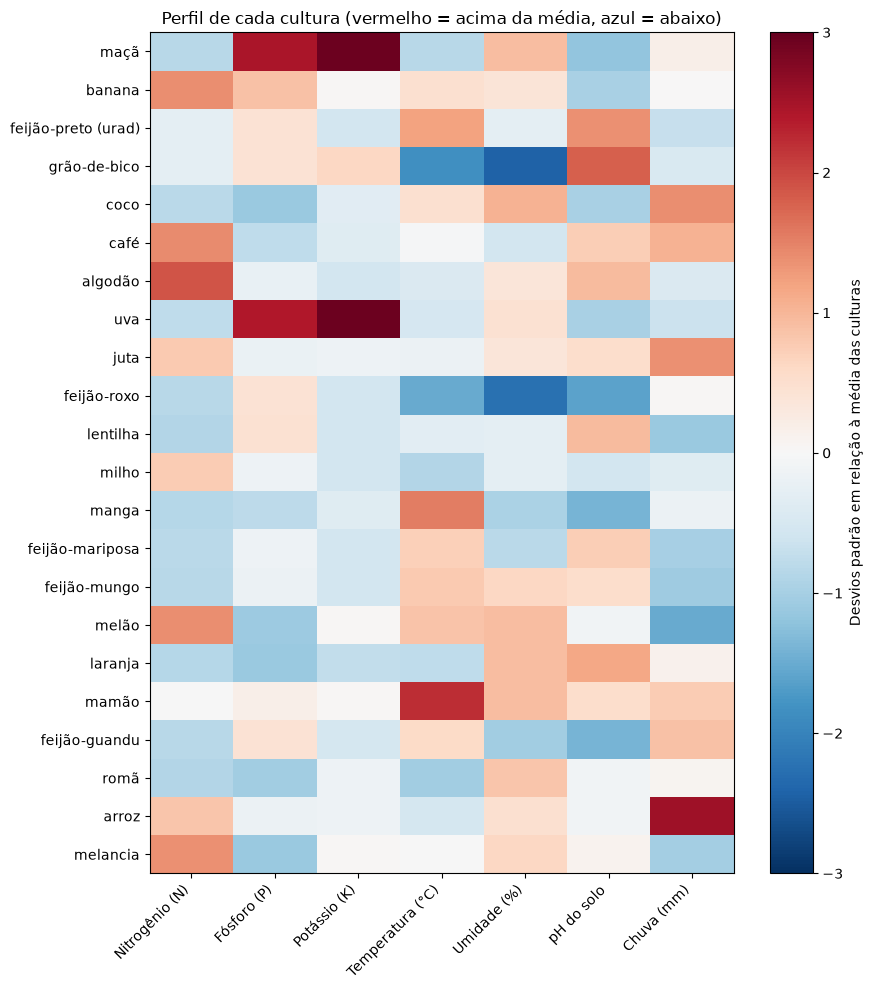

In [8]:
# média de cada variável por cultura, em desvios padrão (para comparar escalas diferentes)
medias_por_cultura = dados.groupby(COLUNA_ALVO)[COLUNAS_ATRIBUTOS].mean().round(1)
medias_por_cultura.index = [NOMES_CULTURAS[c] for c in medias_por_cultura.index]
medias_por_cultura.columns = rotulos
medias_padronizadas = (medias_por_cultura - medias_por_cultura.mean()) / medias_por_cultura.std()

figura, eixo = plt.subplots(figsize=(9, 10))
imagem = eixo.imshow(medias_padronizadas, cmap="RdBu_r", aspect="auto", vmin=-3, vmax=3)
eixo.set_xticks(range(len(rotulos)), rotulos, rotation=45, ha="right")
eixo.set_yticks(range(len(medias_padronizadas)), medias_padronizadas.index)
figura.colorbar(imagem, ax=eixo, label="Desvios padrão em relação à média das culturas")
eixo.set_title("Perfil de cada cultura (vermelho = acima da média, azul = abaixo)")
figura.tight_layout()
salvar_figura(figura, "eda_perfil_culturas.png")
plt.show()

Figura salva em: Figuras\eda_chuva_umidade.png


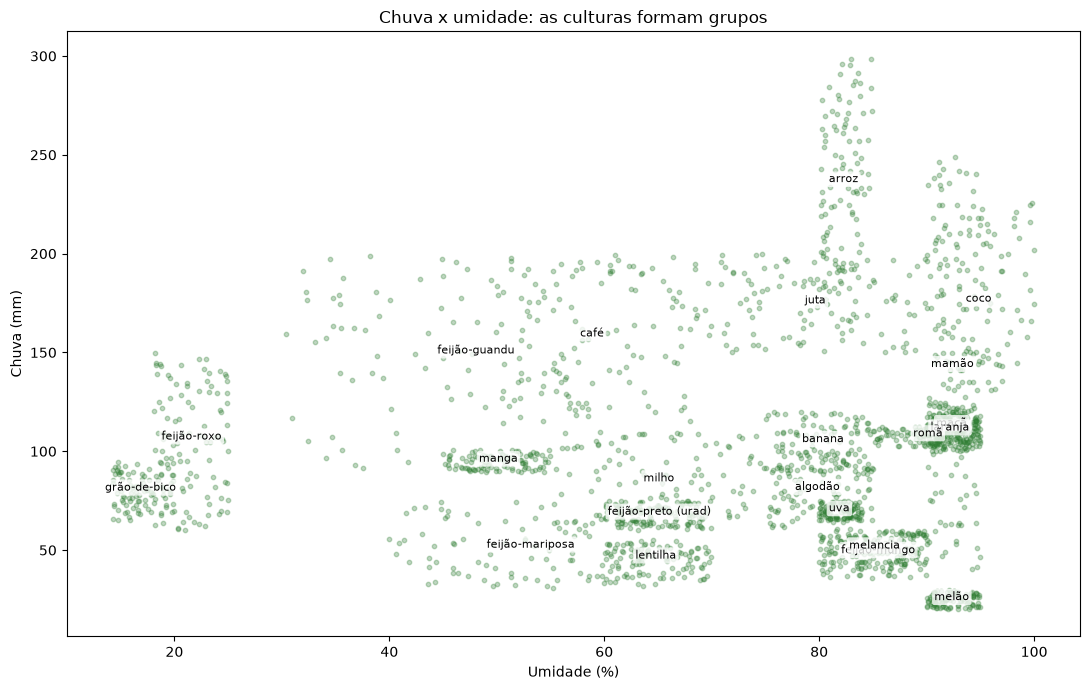

In [9]:
figura, eixo = plt.subplots(figsize=(11, 7))
eixo.scatter(dados["humidity"], dados["rainfall"], s=10, alpha=0.3, color=COR_PRINCIPAL)
centros = dados.groupby(COLUNA_ALVO)[["humidity", "rainfall"]].mean()
for cultura, (umidade, chuva) in centros.iterrows():
    eixo.annotate(NOMES_CULTURAS[cultura], (umidade, chuva), fontsize=8, ha="center",
                  bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "alpha": 0.8, "linewidth": 0})
eixo.set_xlabel(NOMES_ATRIBUTOS["humidity"])
eixo.set_ylabel(NOMES_ATRIBUTOS["rainfall"])
eixo.set_title("Chuva x umidade: as culturas formam grupos")
figura.tight_layout()
salvar_figura(figura, "eda_chuva_umidade.png")
plt.show()

## 3. Pré-processamento

Divisão 80% treino e 20% teste, estratificada pela cultura. O teste só é usado na avaliação final; a escolha dos hiperparâmetros é feita com validação cruzada dentro do treino.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

X = dados[COLUNAS_ATRIBUTOS]
y = dados[COLUNA_ALVO]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Treino:", len(X_treino), "| teste:", len(X_teste))
print("Amostras por cultura - treino:", y_treino.value_counts().unique(), "| teste:", y_teste.value_counts().unique())
print("Ausentes - treino:", int(X_treino.isna().sum().sum()), "| teste:", int(X_teste.isna().sum().sum()))

Treino: 1760 | teste: 440
Amostras por cultura - treino: [80] | teste: [20]
Ausentes - treino: 0 | teste: 0


O XGBoost só aceita o alvo em números, então o `LabelEncoder` (culturas → 0 a 21) é usado apenas nele. Os outros modelos recebem o nome da cultura.

In [11]:
codificador_alvo = LabelEncoder()
y_treino_codificado = codificador_alvo.fit_transform(y_treino)
y_teste_codificado = codificador_alvo.transform(y_teste)

SVM e K-means calculam distâncias, então as variáveis precisam estar na mesma escala (`StandardScaler`). No SVM ele fica dentro do pipeline. Árvores não precisam de padronização. A célula abaixo só mostra o efeito: média 0 e desvio 1 no treino, e valores próximos disso no teste.

Não criamos novas variáveis, porque as 7 medidas já são diretas e as culturas já se separam bem nelas.

In [12]:
escalonador = StandardScaler().fit(X_treino)
pd.DataFrame({
    "média treino": escalonador.transform(X_treino).mean(axis=0),
    "desvio treino": escalonador.transform(X_treino).std(axis=0),
    "média teste": escalonador.transform(X_teste).mean(axis=0),
}, index=COLUNAS_ATRIBUTOS).round(2)

,média treino,desvio treino,média teste
N,0.0,1.0,0.00
P,0.0,1.0,0.00
K,0.0,1.0,0.00
temperature,-0.0,1.0,0.01
humidity,-0.0,1.0,0.01
ph,-0.0,1.0,-0.03
rainfall,0.0,1.0,0.00


## 4. Funções de avaliação e baseline

Todos os modelos são avaliados no teste com acurácia e precision, recall e F1 em média macro (mesmo peso para as 22 culturas).

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

ORDEM_CULTURAS = list(codificador_alvo.classes_)
resultados = {}


def avaliar_modelo(nome_modelo, y_verdadeiro, y_previsto, tempo_treino_s=None, mostrar_relatorio=True):
    metricas = {
        "Acurácia": accuracy_score(y_verdadeiro, y_previsto),
        "Precision (macro)": precision_score(y_verdadeiro, y_previsto, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_verdadeiro, y_previsto, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_verdadeiro, y_previsto, average="macro", zero_division=0),
        "Tempo de treino (s)": tempo_treino_s,
    }
    resultados[nome_modelo] = metricas

    print(f"=== {nome_modelo} (teste, {len(y_verdadeiro)} amostras) ===")
    for nome_metrica, valor in list(metricas.items())[:4]:
        print(f"{nome_metrica:<18} {valor:.4f}")
    if tempo_treino_s is not None:
        print(f"{'Tempo de treino':<18} {tempo_treino_s:.2f} s")
    if mostrar_relatorio:
        nomes_pt = [NOMES_CULTURAS[c] for c in ORDEM_CULTURAS]
        print()
        print(classification_report(y_verdadeiro, y_previsto, labels=ORDEM_CULTURAS,
                                    target_names=nomes_pt, digits=3, zero_division=0))


def plotar_matriz_confusao(nome_modelo, y_verdadeiro, y_previsto, nome_arquivo):
    matriz = confusion_matrix(y_verdadeiro, y_previsto, labels=ORDEM_CULTURAS)
    nomes_pt = [NOMES_CULTURAS[c] for c in ORDEM_CULTURAS]

    figura, eixo = plt.subplots(figsize=(11, 9.5))
    imagem = eixo.imshow(matriz, cmap="Greens")
    eixo.set_xticks(range(len(nomes_pt)), nomes_pt, rotation=90)
    eixo.set_yticks(range(len(nomes_pt)), nomes_pt)
    eixo.set_xlabel("Cultura prevista")
    eixo.set_ylabel("Cultura real")
    for i in range(len(nomes_pt)):
        for j in range(len(nomes_pt)):
            if matriz[i, j] > 0:
                eixo.text(j, i, matriz[i, j], ha="center", va="center", fontsize=8,
                          color="white" if matriz[i, j] > matriz.max() / 2 else "black")
    figura.colorbar(imagem, ax=eixo, label="Quantidade de amostras")
    eixo.set_title(f"Matriz de confusão — {nome_modelo} ({np.trace(matriz)} de {matriz.sum()} acertos)")
    figura.tight_layout()
    salvar_figura(figura, nome_arquivo)
    plt.show()

    # erros fora da diagonal, do mais frequente para o menos
    confusoes = [(nomes_pt[i], nomes_pt[j], int(matriz[i, j]))
                 for i in range(len(nomes_pt)) for j in range(len(nomes_pt))
                 if i != j and matriz[i, j] > 0]
    for real, prevista, quantidade in sorted(confusoes, key=lambda item: -item[2]):
        print(f"  {real} -> {prevista}: {quantidade}")
    return matriz


def tabela_resultados():
    return pd.DataFrame(resultados).T.sort_values("F1 (macro)", ascending=False).round(4)

In [14]:
from sklearn.dummy import DummyClassifier

# baseline: sempre prevê a cultura mais frequente do treino
modelo_baseline = DummyClassifier(strategy="most_frequent")
inicio = time.perf_counter()
modelo_baseline.fit(X_treino, y_treino)
tempo_baseline = time.perf_counter() - inicio

previsoes_baseline = modelo_baseline.predict(X_teste)
avaliar_modelo("Baseline (DummyClassifier)", y_teste, previsoes_baseline,
               tempo_treino_s=tempo_baseline, mostrar_relatorio=False)

=== Baseline (DummyClassifier) (teste, 440 amostras) ===
Acurácia           0.0455
Precision (macro)  0.0021
Recall (macro)     0.0455
F1 (macro)         0.0040
Tempo de treino    0.00 s


O baseline acerta 4,5% (1 em 22), que é o mesmo que chutar. É o mínimo que os modelos precisam superar.

## 5. SVM

Os hiperparâmetros de todos os modelos são escolhidos com `GridSearchCV`: validação cruzada estratificada de 5 partes, só no treino, usando o F1 macro. No SVM testamos o kernel linear e o RBF, cada um com a sua grade.

In [15]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

VALIDACAO_CRUZADA = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def contar_combinacoes(grade):
    total = 1
    for valores in grade.values():
        total *= len(valores)
    return total


def ajustar_com_grid_search(estimador, grade, X_ajuste, y_ajuste):
    busca = GridSearchCV(estimador, grade, scoring="f1_macro", cv=VALIDACAO_CRUZADA, n_jobs=-1, refit=True)
    busca.fit(X_ajuste, y_ajuste)
    print("Combinações testadas:", contar_combinacoes(grade))
    print("Melhores hiperparâmetros:", busca.best_params_)
    print(f"F1 macro na validação cruzada: {busca.best_score_:.4f}")
    return busca


def medir_tempo_treino(modelo, X_ajuste, y_ajuste):
    inicio = time.perf_counter()
    modelo.fit(X_ajuste, y_ajuste)
    return time.perf_counter() - inicio

In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

VALORES_C = [0.1, 1, 5, 10, 100]
grades_svm = {
    "linear": {"svc__C": VALORES_C},
    "rbf": {"svc__C": VALORES_C, "svc__gamma": ["scale", 0.01, 0.1, 1]},
}

buscas_svm = {}
for nome_kernel, grade in grades_svm.items():
    print(f"--- Kernel {nome_kernel} ---")
    pipeline_svm = make_pipeline(StandardScaler(), SVC(kernel=nome_kernel, random_state=RANDOM_STATE))
    buscas_svm[nome_kernel] = ajustar_com_grid_search(pipeline_svm, grade, X_treino, y_treino)
    print()

melhor_kernel = max(buscas_svm, key=lambda k: buscas_svm[k].best_score_)
modelo_svm = buscas_svm[melhor_kernel].best_estimator_
tempo_svm = medir_tempo_treino(modelo_svm, X_treino, y_treino)
print("Kernel escolhido:", melhor_kernel)

--- Kernel linear ---


Combinações testadas: 5
Melhores hiperparâmetros: {'svc__C': 10}
F1 macro na validação cruzada: 0.9857

--- Kernel rbf ---


Combinações testadas: 20
Melhores hiperparâmetros: {'svc__C': 1, 'svc__gamma': 1}
F1 macro na validação cruzada: 0.9846

Kernel escolhido: linear


=== SVM (teste, 440 amostras) ===
Acurácia           0.9886
Precision (macro)  0.9897
Recall (macro)     0.9886
F1 (macro)         0.9886
Tempo de treino    0.02 s

                     precision    recall  f1-score   support

               maçã      1.000     1.000     1.000        20
             banana      1.000     1.000     1.000        20
feijão-preto (urad)      1.000     1.000     1.000        20
       grão-de-bico      1.000     1.000     1.000        20
               coco      1.000     1.000     1.000        20
               café      1.000     1.000     1.000        20
            algodão      0.952     1.000     0.976        20
                uva      1.000     1.000     1.000        20
               juta      0.870     1.000     0.930        20
        feijão-roxo      1.000     1.000     1.000        20
           lentilha      0.952     1.000     0.976        20
              milho      1.000     0.950     0.974        20
              manga      1.000     1.000 

Figura salva em: Figuras\matriz_confusao_svm.png


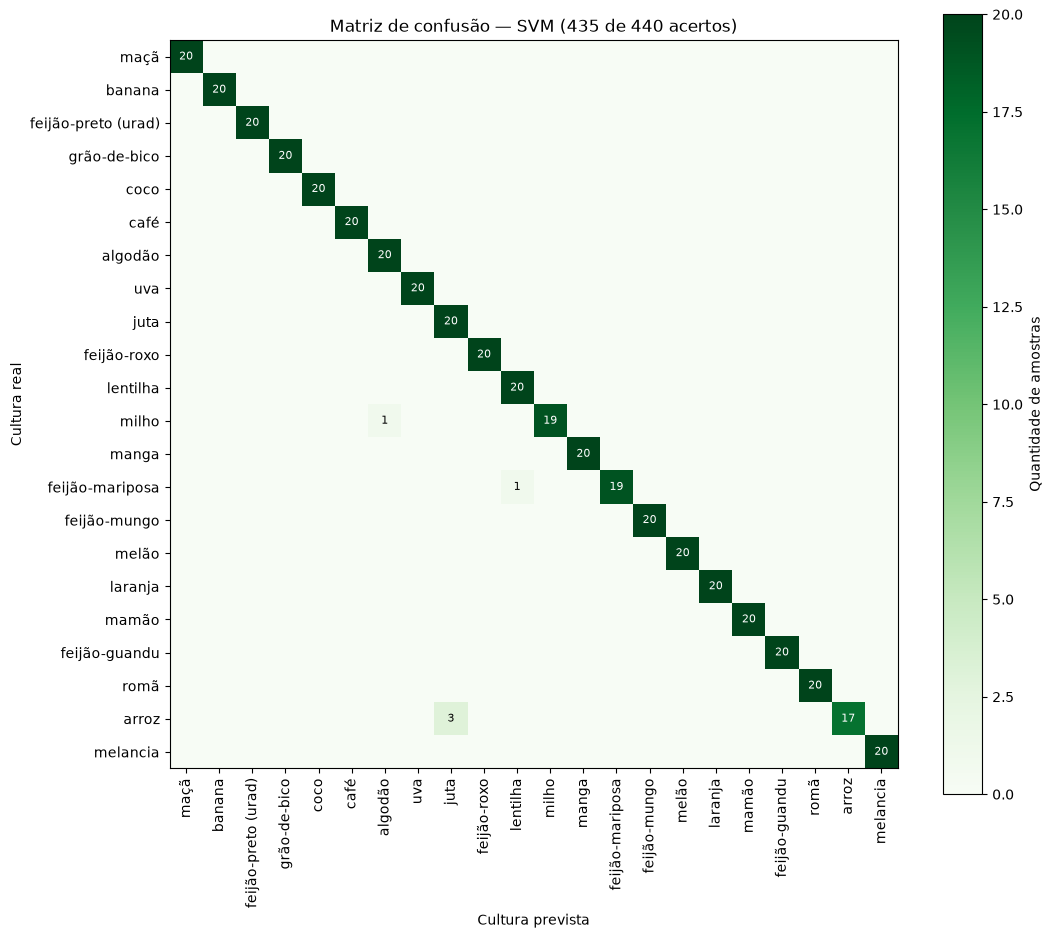

  arroz -> juta: 3
  milho -> algodão: 1
  feijão-mariposa -> lentilha: 1


In [17]:
previsoes_svm = modelo_svm.predict(X_teste)
avaliar_modelo("SVM", y_teste, previsoes_svm, tempo_treino_s=tempo_svm)
matriz_svm = plotar_matriz_confusao("SVM", y_teste, previsoes_svm, "matriz_confusao_svm.png")

Os dois kernels ficaram praticamente empatados na validação, e o linear foi escolhido por ser o mais simples.

## 6. Árvore de Decisão

A árvore não precisa de padronização, então recebe `X_treino` direto.

In [18]:
from sklearn.tree import DecisionTreeClassifier, export_text

grade_arvore = {
    "max_depth": [2, 3, 4, 5, None],
    "min_samples_leaf": [1, 2, 4, 6],
    "criterion": ["gini", "entropy"],
    "ccp_alpha": [0.0, 0.001, 0.01],
}
busca_arvore = ajustar_com_grid_search(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                       grade_arvore, X_treino, y_treino)
modelo_arvore = busca_arvore.best_estimator_
tempo_arvore = medir_tempo_treino(modelo_arvore, X_treino, y_treino)

Combinações testadas: 120
Melhores hiperparâmetros: {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 2}
F1 macro na validação cruzada: 0.9858


=== Árvore de Decisão (teste, 440 amostras) ===
Acurácia           0.9795
Precision (macro)  0.9806
Recall (macro)     0.9795
F1 (macro)         0.9794
Tempo de treino    0.01 s

                     precision    recall  f1-score   support

               maçã      1.000     1.000     1.000        20
             banana      1.000     1.000     1.000        20
feijão-preto (urad)      1.000     0.800     0.889        20
       grão-de-bico      1.000     1.000     1.000        20
               coco      1.000     1.000     1.000        20
               café      1.000     1.000     1.000        20
            algodão      1.000     1.000     1.000        20
                uva      1.000     1.000     1.000        20
               juta      0.950     0.950     0.950        20
        feijão-roxo      1.000     1.000     1.000        20
           lentilha      0.857     0.900     0.878        20
              milho      0.952     1.000     0.976        20
              manga      1.

Figura salva em: Figuras\matriz_confusao_arvore.png


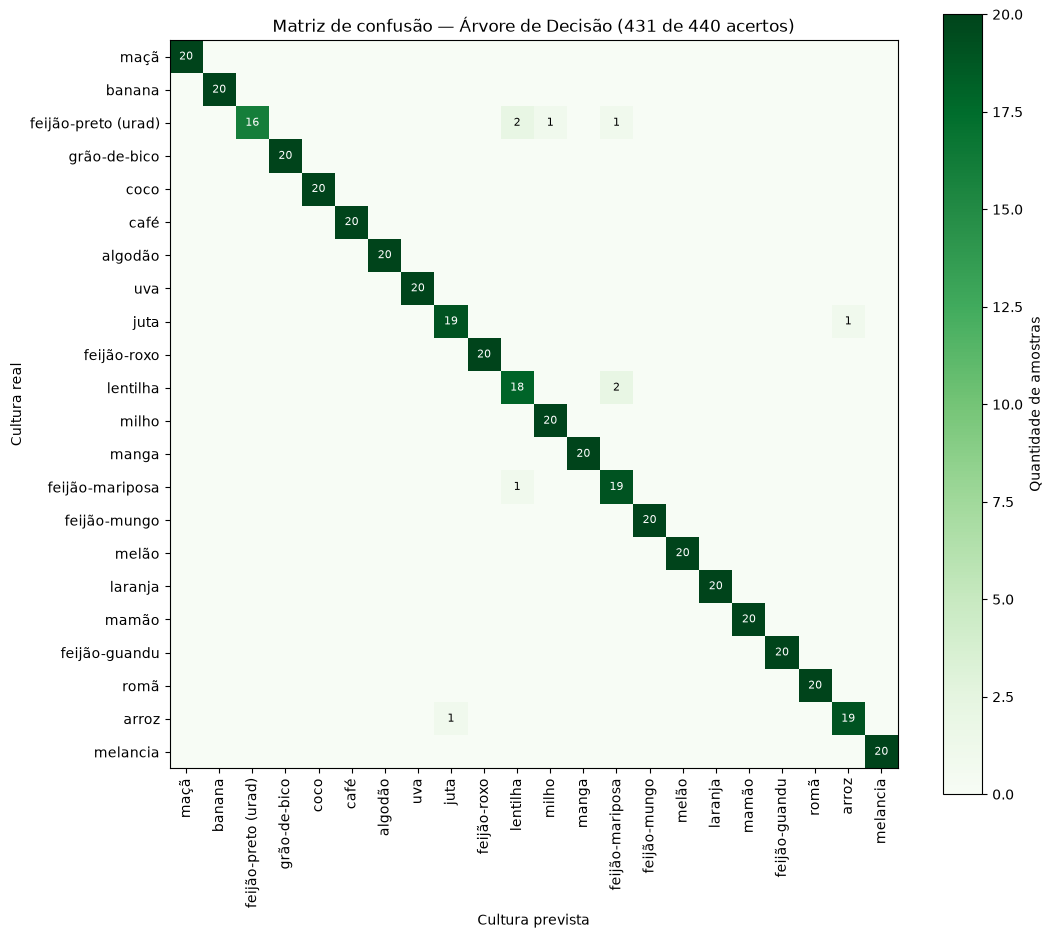

  feijão-preto (urad) -> lentilha: 2
  lentilha -> feijão-mariposa: 2
  feijão-preto (urad) -> milho: 1
  feijão-preto (urad) -> feijão-mariposa: 1
  juta -> arroz: 1
  feijão-mariposa -> lentilha: 1
  arroz -> juta: 1


In [19]:
previsoes_arvore = modelo_arvore.predict(X_teste)
avaliar_modelo("Árvore de Decisão", y_teste, previsoes_arvore, tempo_treino_s=tempo_arvore)
matriz_arvore = plotar_matriz_confusao("Árvore de Decisão", y_teste, previsoes_arvore, "matriz_confusao_arvore.png")

In [20]:
print("Folhas:", modelo_arvore.get_n_leaves(), "| profundidade:", modelo_arvore.get_depth())
regras_arvore = export_text(modelo_arvore, feature_names=COLUNAS_ATRIBUTOS)
print("\n".join(regras_arvore.splitlines()[:30]))
print("...")

Folhas: 37 | profundidade: 17
|--- rainfall <= 30.18
|   |--- class: muskmelon
|--- rainfall >  30.18
|   |--- humidity <= 27.98
|   |   |--- K <= 50.00
|   |   |   |--- class: kidneybeans
|   |   |--- K >  50.00
|   |   |   |--- class: chickpea
|   |--- humidity >  27.98
|   |   |--- P <= 107.50
|   |   |   |--- humidity <= 70.65
|   |   |   |   |--- N <= 59.50
|   |   |   |   |   |--- rainfall <= 82.25
|   |   |   |   |   |   |--- P <= 59.50
|   |   |   |   |   |   |   |--- humidity <= 65.01
|   |   |   |   |   |   |   |   |--- N <= 45.00
|   |   |   |   |   |   |   |   |   |--- temperature <= 23.61
|   |   |   |   |   |   |   |   |   |   |--- class: lentil
|   |   |   |   |   |   |   |   |   |--- temperature >  23.61
|   |   |   |   |   |   |   |   |   |   |--- humidity <= 63.75
|   |   |   |   |   |   |   |   |   |   |   |--- class: mothbeans
|   |   |   |   |   |   |   |   |   |   |--- humidity >  63.75
|   |   |   |   |   |   |   |   |   |   |   |--- class: mothbeans
|   |   |   

Para ver o efeito da profundidade, mantivemos os outros hiperparâmetros e variamos `max_depth` e `criterion` (validação cruzada no treino):

In [21]:
from sklearn.model_selection import cross_val_score

linhas_profundidade = []
for criterio in ["gini", "entropy"]:
    for profundidade_maxima in [3, 5, 8, None]:
        parametros = {**busca_arvore.best_params_, "criterion": criterio, "max_depth": profundidade_maxima}
        arvore_teste = DecisionTreeClassifier(**parametros, random_state=RANDOM_STATE)
        notas = cross_val_score(arvore_teste, X_treino, y_treino, cv=VALIDACAO_CRUZADA, scoring="f1_macro")
        arvore_teste.fit(X_treino, y_treino)
        linhas_profundidade.append({
            "Critério": criterio,
            "max_depth": "sem limite" if profundidade_maxima is None else profundidade_maxima,
            "Folhas": arvore_teste.get_n_leaves(),
            "Profundidade real": arvore_teste.get_depth(),
            "F1 macro (validação)": round(notas.mean(), 4),
        })

tabela_profundidade = pd.DataFrame(linhas_profundidade).set_index(["Critério", "max_depth"])
tabela_profundidade

Folhas  Profundidade real  F1 macro (validação)
Critério max_depth                                                  
gini     3                5                  3                0.1706
         5                9                  5                0.3110
         8               21                  8                0.8446
         sem limite      37                 17                0.9858
entropy  3                8                  3                0.2084
         5               24                  5                0.8973
         8               37                  8                0.9770
         sem limite      42                 12                0.9783

Limitar a profundidade derruba o resultado (com 22 culturas a árvore precisa de muitas perguntas). Isso explica os ~87% de alguns artigos, que usaram `max_depth=5`.

## 7. Ensembles: Random Forest e XGBoost

Random Forest (bagging): árvores treinadas em paralelo que votam. XGBoost (boosting): árvores em sequência, cada uma corrigindo os erros das anteriores.

In [22]:
from sklearn.ensemble import RandomForestClassifier

grade_floresta = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_leaf": [1, 3],
    "max_features": ["sqrt", 0.8],
}
busca_floresta = ajustar_com_grid_search(RandomForestClassifier(random_state=RANDOM_STATE),
                                         grade_floresta, X_treino, y_treino)
modelo_floresta = busca_floresta.best_estimator_
tempo_floresta = medir_tempo_treino(modelo_floresta, X_treino, y_treino)

Combinações testadas: 16
Melhores hiperparâmetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
F1 macro na validação cruzada: 0.9943


=== Random Forest (teste, 440 amostras) ===
Acurácia           0.9955
Precision (macro)  0.9957
Recall (macro)     0.9955
F1 (macro)         0.9955
Tempo de treino    0.45 s

                     precision    recall  f1-score   support

               maçã      1.000     1.000     1.000        20
             banana      1.000     1.000     1.000        20
feijão-preto (urad)      1.000     0.950     0.974        20
       grão-de-bico      1.000     1.000     1.000        20
               coco      1.000     1.000     1.000        20
               café      1.000     1.000     1.000        20
            algodão      1.000     1.000     1.000        20
                uva      1.000     1.000     1.000        20
               juta      0.952     1.000     0.976        20
        feijão-roxo      1.000     1.000     1.000        20
           lentilha      1.000     1.000     1.000        20
              milho      0.952     1.000     0.976        20
              manga      1.000 

Figura salva em: Figuras\matriz_confusao_random_forest.png


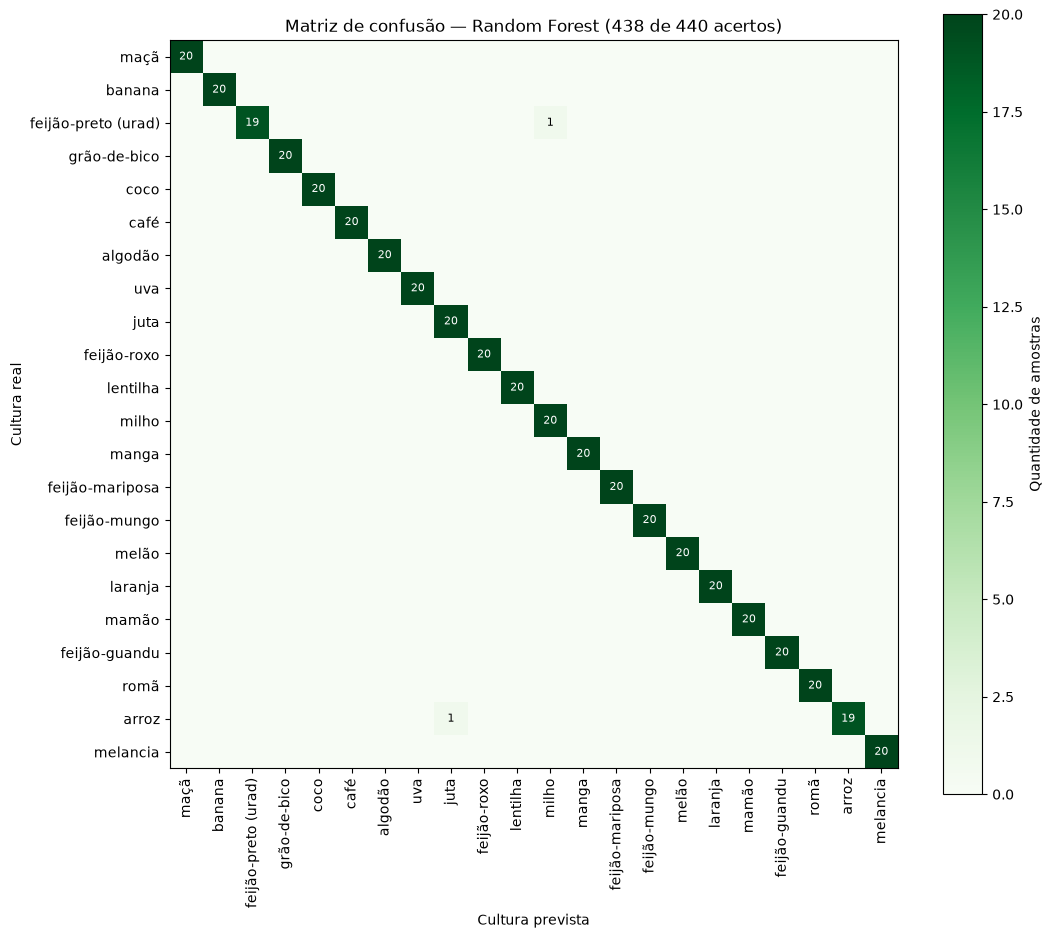

  feijão-preto (urad) -> milho: 1
  arroz -> juta: 1


In [23]:
previsoes_floresta = modelo_floresta.predict(X_teste)
avaliar_modelo("Random Forest", y_teste, previsoes_floresta, tempo_treino_s=tempo_floresta)
matriz_floresta = plotar_matriz_confusao("Random Forest", y_teste, previsoes_floresta, "matriz_confusao_random_forest.png")

In [24]:
from xgboost import XGBClassifier

grade_xgboost = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.85, 1.0],
}
# o XGBoost usa o alvo codificado (0 a 21)
busca_xgboost = ajustar_com_grid_search(XGBClassifier(random_state=RANDOM_STATE, n_jobs=1),
                                        grade_xgboost, X_treino, y_treino_codificado)
modelo_xgboost = busca_xgboost.best_estimator_
tempo_xgboost = medir_tempo_treino(modelo_xgboost, X_treino, y_treino_codificado)

Combinações testadas: 16
Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 1.0}
F1 macro na validação cruzada: 0.9920


=== XGBoost (teste, 440 amostras) ===
Acurácia           0.9864
Precision (macro)  0.9874
Recall (macro)     0.9864
F1 (macro)         0.9862
Tempo de treino    0.54 s

                     precision    recall  f1-score   support

               maçã      1.000     1.000     1.000        20
             banana      1.000     1.000     1.000        20
feijão-preto (urad)      0.952     1.000     0.976        20
       grão-de-bico      1.000     1.000     1.000        20
               coco      1.000     1.000     1.000        20
               café      1.000     1.000     1.000        20
            algodão      1.000     1.000     1.000        20
                uva      1.000     1.000     1.000        20
               juta      0.909     1.000     0.952        20
        feijão-roxo      1.000     1.000     1.000        20
           lentilha      1.000     0.850     0.919        20
              milho      1.000     1.000     1.000        20
              manga      1.000     1.

Figura salva em: Figuras\matriz_confusao_xgboost.png


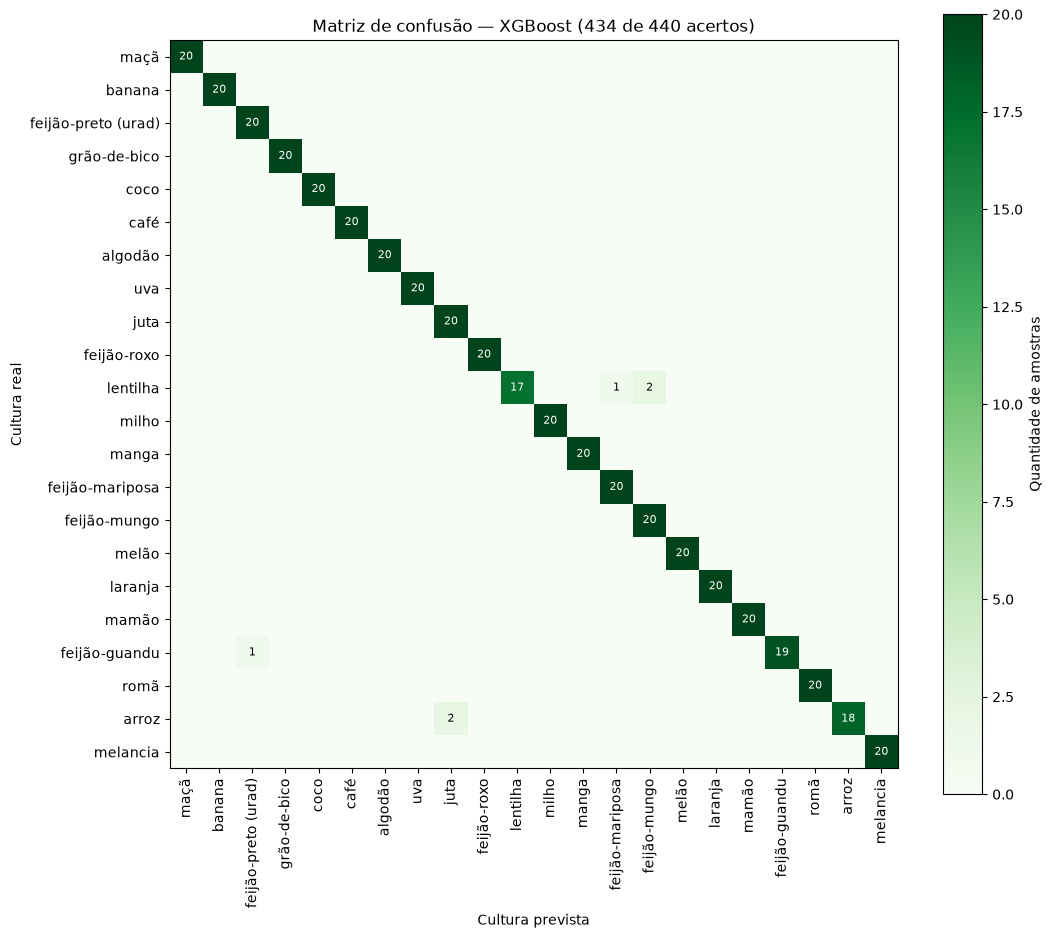

  lentilha -> feijão-mungo: 2
  arroz -> juta: 2
  lentilha -> feijão-mariposa: 1
  feijão-guandu -> feijão-preto (urad): 1


In [25]:
previsoes_xgboost = codificador_alvo.inverse_transform(modelo_xgboost.predict(X_teste))
avaliar_modelo("XGBoost", y_teste, previsoes_xgboost, tempo_treino_s=tempo_xgboost)
matriz_xgboost = plotar_matriz_confusao("XGBoost", y_teste, previsoes_xgboost, "matriz_confusao_xgboost.png")

## 8. K-means

Agora sem usar a cultura: o K-means agrupa as 2.200 áreas só pelas 7 medidas, e depois olhamos quais culturas caíram em cada grupo. Cada grupo é chamado de **zona** (um tipo de ambiente, não uma região do mapa, já que o dataset não tem localização). As variáveis são padronizadas porque o K-means usa distância.

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

X_agrupamento = dados[COLUNAS_ATRIBUTOS].copy()


def criar_preparacao():
    return make_pipeline(StandardScaler())


preparacao = criar_preparacao()
Z = preparacao.fit_transform(X_agrupamento)

Testamos K de 2 a 12 olhando a inércia, a silhueta e a estabilidade. A estabilidade é medida pelo ARI: refazemos o agrupamento com 80% das áreas e comparamos com a divisão completa (1 = mesma divisão).

In [27]:
def ari_subamostras(k, rotulos_referencia, quantidade_ensaios):
    aris = []
    n = len(X_agrupamento)
    for semente in range(quantidade_ensaios):
        rng = np.random.default_rng(semente)
        indices = rng.choice(n, int(0.8 * n), replace=False)
        prep_amostra = criar_preparacao()
        Z_amostra = prep_amostra.fit_transform(X_agrupamento.iloc[indices])
        modelo_amostra = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z_amostra)
        previstos = modelo_amostra.predict(prep_amostra.transform(X_agrupamento))
        aris.append(adjusted_rand_score(rotulos_referencia, previstos))
    return np.array(aris)


VALORES_K = range(2, 13)
avaliacoes = []
modelos_kmeans = {}
for k in VALORES_K:
    candidato = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=RANDOM_STATE)
    rotulos_k = candidato.fit_predict(Z)
    avaliacoes.append([k, candidato.inertia_, silhouette_score(Z, rotulos_k)])
    modelos_kmeans[k] = candidato
avaliacao_k = pd.DataFrame(avaliacoes, columns=["k", "inercia", "silhueta"])

aris = [ari_subamostras(k, modelos_kmeans[k].labels_, quantidade_ensaios=10) for k in VALORES_K]
avaliacao_k["ari_subamostra_min"] = [a.min() for a in aris]
avaliacao_k["ari_subamostra_mediana"] = [np.median(a) for a in aris]
avaliacao_k.round(3)

,k,inercia,silhueta,ari_subamostra_min,ari_subamostra_mediana
0,2,11738.011,0.417,1.000,1.000
1,3,9489.462,0.252,0.987,0.996
2,4,8105.864,0.255,0.382,0.991
3,5,6856.212,0.292,0.855,0.990
4,6,6045.093,0.304,0.723,0.982
5,7,5248.626,0.333,0.985,0.991
6,8,4842.083,0.327,0.753,0.990
7,9,4472.455,0.332,0.829,0.893
8,10,4110.154,0.349,0.883,0.944
9,11,3845.097,0.347,0.820,0.976


Figura salva em: Figuras\kmeans_escolha_k.png


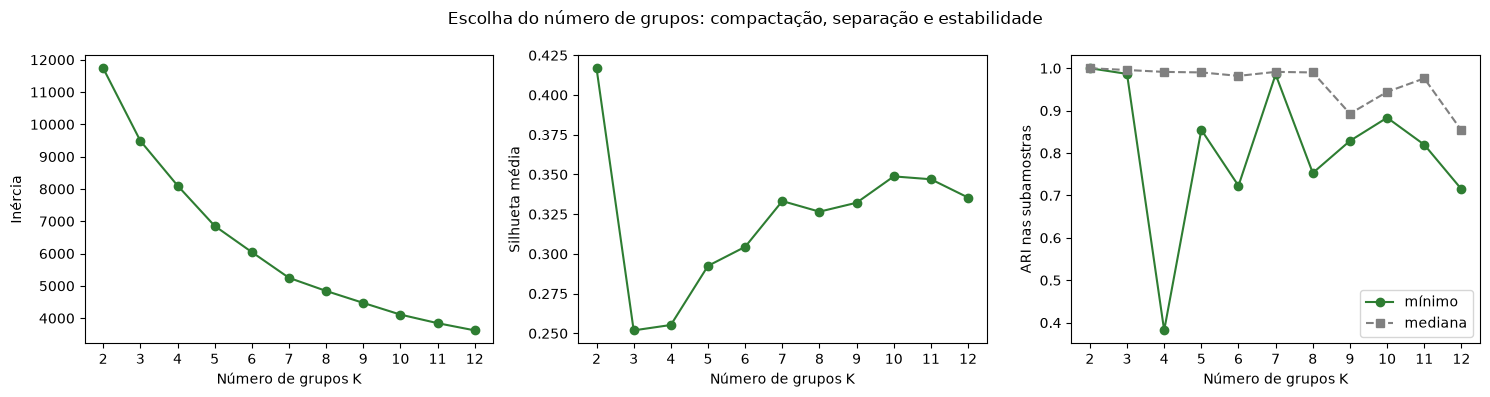

In [28]:
figura, eixos = plt.subplots(1, 3, figsize=(15, 4))
eixos[0].plot(avaliacao_k["k"], avaliacao_k["inercia"], "o-", color=COR_PRINCIPAL)
eixos[0].set_ylabel("Inércia")
eixos[1].plot(avaliacao_k["k"], avaliacao_k["silhueta"], "o-", color=COR_PRINCIPAL)
eixos[1].set_ylabel("Silhueta média")
eixos[2].plot(avaliacao_k["k"], avaliacao_k["ari_subamostra_min"], "o-", color=COR_PRINCIPAL, label="mínimo")
eixos[2].plot(avaliacao_k["k"], avaliacao_k["ari_subamostra_mediana"], "s--", color="gray", label="mediana")
eixos[2].set_ylabel("ARI nas subamostras")
eixos[2].legend()
for eixo in eixos:
    eixo.set_xlabel("Número de grupos K")
    eixo.set_xticks(list(VALORES_K))
figura.suptitle("Escolha do número de grupos: compactação, separação e estabilidade")
figura.tight_layout()
salvar_figura(figura, "kmeans_escolha_k.png")
plt.show()

Escolhemos **K = 7**. K = 2 tem a maior silhueta, mas só separa maçã e uva do resto. Entre 3 e 9 grupos, o K = 7 tem a melhor silhueta e é estável nas subamostras. A inércia não mostra um cotovelo claro.

Os grupos foram renumerados do mais seco ao mais chuvoso (pela mediana da chuva).

In [29]:
k_escolhido = 7
modelo_kmeans = modelos_kmeans[k_escolhido]

base_agrupada = dados.copy()
base_agrupada["rotulo_original"] = modelo_kmeans.labels_
ordem_grupos = base_agrupada.groupby("rotulo_original")["rainfall"].median().sort_values().index
mapa_grupos = {rotulo: numero for numero, rotulo in enumerate(ordem_grupos, start=1)}
base_agrupada["grupo"] = base_agrupada["rotulo_original"].map(mapa_grupos)
grupos = base_agrupada["grupo"].to_numpy()
LISTA_GRUPOS = sorted(base_agrupada["grupo"].unique())

base_agrupada["grupo"].value_counts().sort_index().rename("Áreas").to_frame()

,Áreas
grupo,
1,430
2,524
3,200
4,222
5,198
6,291
7,335


In [30]:
# mediana (e quartis 25% a 75%) de cada variável por grupo
separados = base_agrupada.groupby("grupo")
perfil_mediano = separados[COLUNAS_ATRIBUTOS].median()
quartil_25 = separados[COLUNAS_ATRIBUTOS].quantile(0.25)
quartil_75 = separados[COLUNAS_ATRIBUTOS].quantile(0.75)

perfil_grupos = pd.DataFrame(index=perfil_mediano.index)
for coluna in COLUNAS_ATRIBUTOS:
    perfil_grupos[NOMES_ATRIBUTOS[coluna]] = [
        f"{perfil_mediano.loc[g, coluna]:.1f} ({quartil_25.loc[g, coluna]:.0f} a {quartil_75.loc[g, coluna]:.0f})"
        for g in perfil_mediano.index
    ]

# a cultura só entra aqui, depois do agrupamento
culturas_por_grupo = pd.crosstab(base_agrupada["grupo"], base_agrupada[COLUNA_ALVO])
perfil_grupos["Áreas"] = culturas_por_grupo.sum(axis=1)
perfil_grupos["Culturas principais"] = [
    ", ".join(NOMES_CULTURAS[c] for c in culturas_por_grupo.loc[g][culturas_por_grupo.loc[g] >= 50]
              .sort_values(ascending=False).index)
    for g in culturas_por_grupo.index
]
perfil_grupos

,Nitrogênio (N),Fósforo (P),Potássio (K),Temperatura (°C),Umidade (%),pH do solo,Chuva (mm),Áreas,Culturas principais
grupo,,,,,,,,,
1,28.0 (15 a 38),59.0 (47 a 67),20.0 (17 a 23),28.6 (27 a 31),66.8 (62 a 85),7.0 (7 a 7),56.0 (45 a 70),430,"feijão-preto (urad), feijão-mungo, lentilha, f..."
2,100.0 (86 a 112),40.0 (21 a 58),46.0 (21 a 51),25.7 (24 a 28),81.6 (76 a 88),6.4 (6 a 7),72.7 (48 a 96),524,"banana, algodão, melão, melancia, milho"
3,24.0 (11 a 32),135.0 (126 a 140),200.0 (197 a 203),22.6 (21 a 24),87.0 (82 a 92),5.9 (6 a 6),87.5 (70 a 113),200,"maçã, uva"
4,28.0 (19 a 39),68.0 (61 a 74),24.0 (20 a 79),19.3 (18 a 21),19.4 (17 a 23),6.1 (6 a 7),87.8 (76 a 109),222,"grão-de-bico, feijão-roxo"
5,21.0 (9 a 31),43.5 (29 a 61),24.0 (20 a 30),30.0 (28 a 32),50.1 (46 a 54),5.5 (5 a 6),96.0 (90 a 121),198,"manga, feijão-guandu"
6,20.0 (9 a 31),18.0 (10 a 24),31.0 (13 a 38),24.5 (20 a 27),92.0 (91 a 94),6.4 (6 a 7),111.8 (107 a 149),291,"romã, coco, laranja"
7,81.0 (67 a 92),45.0 (36 a 55),39.0 (35 a 43),25.2 (24 a 27),80.9 (70 a 84),6.7 (6 a 7),189.4 (168 a 218),335,"juta, arroz, café"


O mapa abaixo mostra a média padronizada de cada variável em cada zona (0 = média geral). Foi a partir dele que demos um nome para cada zona.

Figura salva em: Figuras\kmeans_perfil_zonas.png


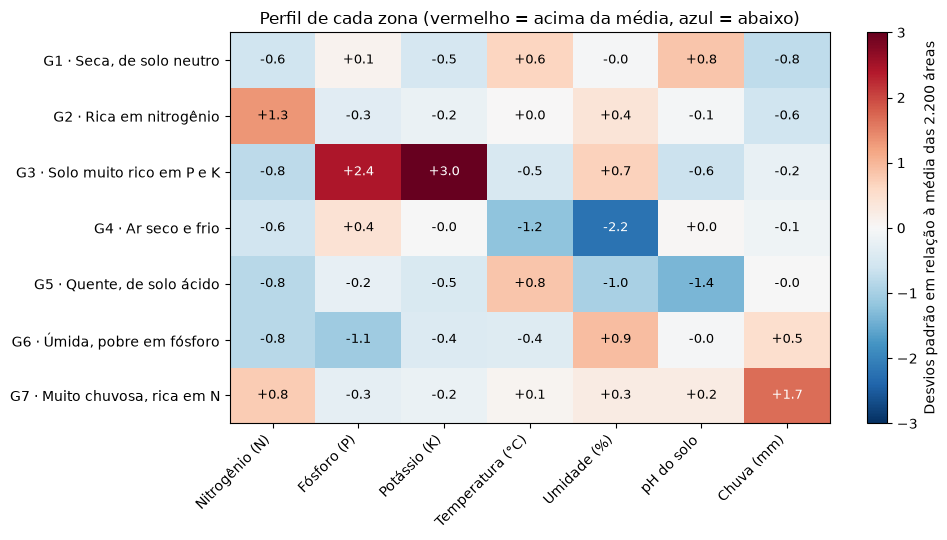

,Zona,Destaques (desvios padrão),Áreas,Culturas principais
grupo,,,,
1,"Seca, de solo neutro","pH do solo +0.8, Chuva (mm) -0.8",430,"feijão-preto (urad), feijão-mungo, lentilha, f..."
2,Rica em nitrogênio,"Nitrogênio (N) +1.3, Chuva (mm) -0.6",524,"banana, algodão, melão, melancia, milho"
3,Solo muito rico em P e K,"Potássio (K) +3.0, Fósforo (P) +2.4",200,"maçã, uva"
4,Ar seco e frio,"Umidade (%) -2.2, Temperatura (°C) -1.2",222,"grão-de-bico, feijão-roxo"
5,"Quente, de solo ácido","pH do solo -1.4, Umidade (%) -1.0",198,"manga, feijão-guandu"
6,"Úmida, pobre em fósforo","Fósforo (P) -1.1, Umidade (%) +0.9",291,"romã, coco, laranja"
7,"Muito chuvosa, rica em N","Chuva (mm) +1.7, Nitrogênio (N) +0.8",335,"juta, arroz, café"


In [31]:
centroides_padronizados = pd.DataFrame(Z, columns=COLUNAS_ATRIBUTOS).groupby(grupos).mean()

NOMES_ZONAS = {
    1: "Seca, de solo neutro",
    2: "Rica em nitrogênio",
    3: "Solo muito rico em P e K",
    4: "Ar seco e frio",
    5: "Quente, de solo ácido",
    6: "Úmida, pobre em fósforo",
    7: "Muito chuvosa, rica em N",
}


def destacar_variaveis(linha, quantidade=2):
    principais = linha.abs().sort_values(ascending=False).index[:quantidade]
    return ", ".join(f"{NOMES_ATRIBUTOS[c]} {linha[c]:+.1f}" for c in principais)


zonas = pd.DataFrame({
    "Zona": [NOMES_ZONAS[g] for g in LISTA_GRUPOS],
    "Destaques (desvios padrão)": [destacar_variaveis(centroides_padronizados.loc[g]) for g in LISTA_GRUPOS],
    "Áreas": perfil_grupos["Áreas"].values,
    "Culturas principais": perfil_grupos["Culturas principais"].values,
}, index=pd.Index(LISTA_GRUPOS, name="grupo"))

figura, eixo = plt.subplots(figsize=(10, 5.5))
imagem = eixo.imshow(centroides_padronizados, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
eixo.set_xticks(range(len(COLUNAS_ATRIBUTOS)), rotulos, rotation=45, ha="right")
eixo.set_yticks(range(len(LISTA_GRUPOS)), [f"G{g} · {NOMES_ZONAS[g]}" for g in LISTA_GRUPOS])
for i, g in enumerate(LISTA_GRUPOS):
    for j, coluna in enumerate(COLUNAS_ATRIBUTOS):
        valor = centroides_padronizados.loc[g, coluna]
        eixo.text(j, i, f"{valor:+.1f}", ha="center", va="center", fontsize=9,
                  color="white" if abs(valor) > 1.5 else "black")
figura.colorbar(imagem, ax=eixo, label="Desvios padrão em relação à média das 2.200 áreas")
eixo.set_title("Perfil de cada zona (vermelho = acima da média, azul = abaixo)")
figura.tight_layout()
salvar_figura(figura, "kmeans_perfil_zonas.png")
plt.show()
zonas

Figura salva em: Figuras\kmeans_culturas_por_zona.png


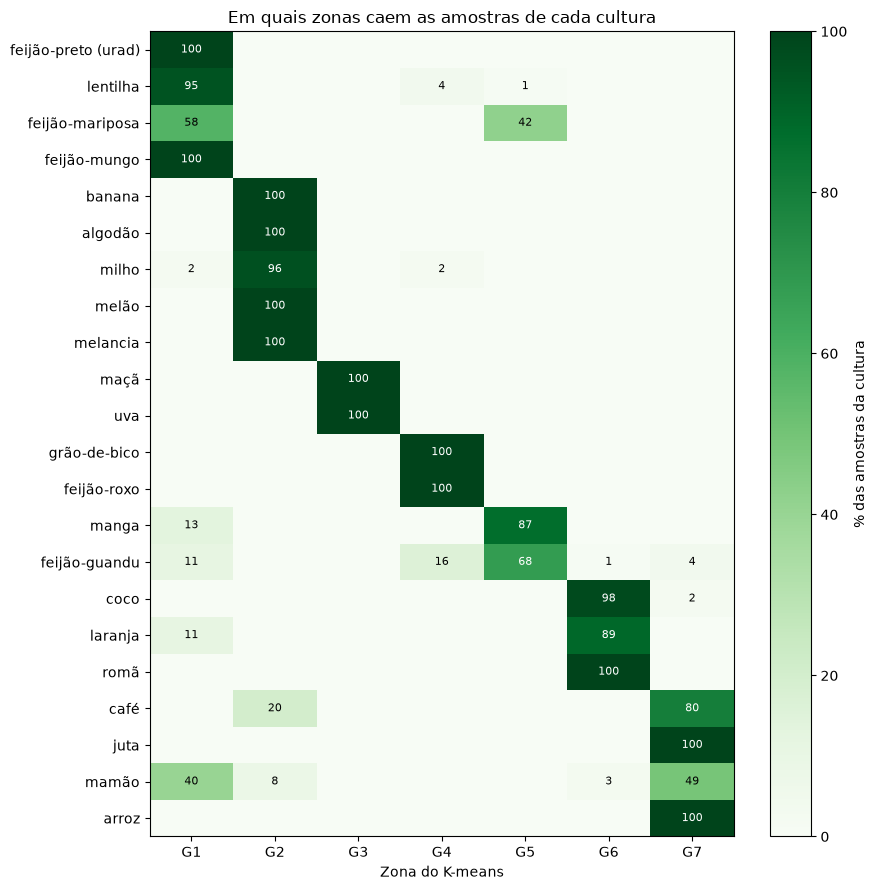

Culturas divididas entre zonas:
- feijão-mariposa: 58% em G1, 42% em G5
- feijão-guandu: 68% em G5, 16% em G4, 11% em G1, 4% em G7, 1% em G6
- mamão: 49% em G7, 40% em G1, 8% em G2, 3% em G6


In [32]:
# cada cultura tem 100 amostras, então a contagem já é o percentual
percentual_culturas = culturas_por_grupo.T
ordem_culturas = percentual_culturas.idxmax(axis=1).sort_values(kind="stable").index
percentual_culturas = percentual_culturas.loc[ordem_culturas]

figura, eixo = plt.subplots(figsize=(9, 9))
imagem = eixo.imshow(percentual_culturas, cmap="Greens", vmin=0, vmax=100, aspect="auto")
eixo.set_xticks(range(len(LISTA_GRUPOS)), [f"G{g}" for g in LISTA_GRUPOS])
eixo.set_yticks(range(len(percentual_culturas)), [NOMES_CULTURAS[c] for c in percentual_culturas.index])
for i in range(percentual_culturas.shape[0]):
    for j in range(percentual_culturas.shape[1]):
        valor = percentual_culturas.iloc[i, j]
        if valor > 0:
            eixo.text(j, i, int(valor), ha="center", va="center", fontsize=8, color="white" if valor > 60 else "black")
figura.colorbar(imagem, ax=eixo, label="% das amostras da cultura")
eixo.set_xlabel("Zona do K-means")
eixo.set_title("Em quais zonas caem as amostras de cada cultura")
figura.tight_layout()
salvar_figura(figura, "kmeans_culturas_por_zona.png")
plt.show()

culturas_divididas = percentual_culturas[percentual_culturas.max(axis=1) < 80]
print("Culturas divididas entre zonas:")
for cultura, linha in culturas_divididas.iterrows():
    partes = linha[linha > 0].sort_values(ascending=False)
    print(f"- {NOMES_CULTURAS[cultura]}: " + ", ".join(f"{n}% em G{g}" for g, n in partes.items()))

A maioria das culturas fica inteira numa só zona. Só feijão-mariposa, feijão-guandu e mamão se dividem entre zonas vizinhas.

Quanto cada variável diferencia as zonas (% da variação explicada pelas diferenças entre os grupos):

In [33]:
contribuicoes = []
for j, coluna in enumerate(COLUNAS_ATRIBUTOS):
    valores = Z[:, j]
    total = ((valores - valores.mean()) ** 2).sum()
    dentro = sum(((valores[grupos == g] - valores[grupos == g].mean()) ** 2).sum() for g in LISTA_GRUPOS)
    contribuicoes.append([NOMES_ATRIBUTOS[coluna], 100 * (1 - dentro / total)])

contribuicao = pd.DataFrame(contribuicoes, columns=["Variável", "Variação entre grupos (%)"])
contribuicao.sort_values("Variação entre grupos (%)", ascending=False).round(1).reset_index(drop=True)

,Variável,Variação entre grupos (%)
0,Potássio (K),92.4
1,Nitrogênio (N),81.2
2,Umidade (%),78.7
3,Fósforo (P),75.3
4,Chuva (mm),66.1
5,pH do solo,34.7
6,Temperatura (°C),33.1


### Estabilidade e áreas de fronteira

Conferimos se a divisão muda com o ponto de partida (`n_init` 1 e 20, com 20 sementes) e com 30 subamostras de 80%. Áreas com silhueta abaixo de 0,20 ficam na fronteira entre duas zonas.

In [34]:
estabilidade_inicio = []
for repeticoes in [1, 20]:
    for semente in range(20):
        teste = KMeans(n_clusters=k_escolhido, n_init=repeticoes, random_state=semente)
        estabilidade_inicio.append([repeticoes, adjusted_rand_score(grupos, teste.fit_predict(Z))])
estabilidade_inicio = pd.DataFrame(estabilidade_inicio, columns=["n_init", "ari"])
print(estabilidade_inicio.groupby("n_init")["ari"].agg(["min", "median"]).round(3))

aris_amostra = ari_subamostras(k_escolhido, grupos, quantidade_ensaios=30)
print(f"\nSubamostras de 80%: ARI mínimo {aris_amostra.min():.3f} | mediano {np.median(aris_amostra):.3f}")

base_agrupada["silhueta"] = silhouette_samples(Z, grupos)
print(f"Silhueta média: {base_agrupada['silhueta'].mean():.3f}")

silhueta_por_zona = base_agrupada.groupby("grupo")["silhueta"].agg(
    silhueta_media="mean", areas_fronteira_pct=lambda s: (s < 0.20).mean() * 100)
silhueta_por_zona.insert(0, "Zona", [NOMES_ZONAS[g] for g in silhueta_por_zona.index])
silhueta_por_zona.round(3)

          min  median
n_init               
1       0.638   0.903
20      1.000   1.000



Subamostras de 80%: ARI mínimo 0.980 | mediano 0.992
Silhueta média: 0.333


,Zona,silhueta_media,areas_fronteira_pct
grupo,,,
1,"Seca, de solo neutro",0.290,22.791
2,Rica em nitrogênio,0.320,15.840
3,Solo muito rico em P e K,0.624,0.000
4,Ar seco e frio,0.348,13.964
5,"Quente, de solo ácido",0.282,30.303
6,"Úmida, pobre em fósforo",0.313,15.464
7,"Muito chuvosa, rica em N",0.274,24.478


A zona 3 (maçã e uva) é a mais bem definida. As zonas 5, 7 e 1 têm mais áreas de fronteira, justamente onde estão as culturas divididas.

Sem a padronização, chuva e potássio dominam a distância e os grupos mudam bastante:

In [35]:
grupos_sem_padronizar = KMeans(n_clusters=k_escolhido, n_init=20, random_state=RANDOM_STATE).fit_predict(X_agrupamento.to_numpy())
print(f"ARI sem padronização x divisão escolhida: {adjusted_rand_score(grupos, grupos_sem_padronizar):.3f}")

participacao_variancia = (X_agrupamento.var() / X_agrupamento.var().sum() * 100).round(1)
participacao_variancia.rename(NOMES_ATRIBUTOS).rename("% da variância bruta").to_frame()

ARI sem padronização x divisão escolhida: 0.629


,% da variância bruta
Nitrogênio (N),15.9
Fósforo (P),12.7
Potássio (K),30.0
Temperatura (°C),0.3
Umidade (%),5.8
pH do solo,0.0
Chuva (mm),35.3


### Agrupamento só com o clima

Testamos se temperatura, umidade e chuva sozinhas formariam "regiões climáticas" melhores. Usamos o mesmo K = 7 para comparar.

In [36]:
COLUNAS_CLIMA = ["temperature", "humidity", "rainfall"]
Z_clima = criar_preparacao().fit_transform(dados[COLUNAS_CLIMA])

silhuetas_clima = {k: silhouette_score(Z_clima, KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(Z_clima))
                   for k in VALORES_K}
print("Silhueta só com clima:", {k: round(s, 3) for k, s in silhuetas_clima.items()})

modelo_clima = KMeans(n_clusters=k_escolhido, n_init=20, random_state=RANDOM_STATE).fit(Z_clima)
regioes_clima = modelo_clima.labels_
culturas_por_regiao = pd.crosstab(regioes_clima, dados[COLUNA_ALVO])

perfil_clima = dados.groupby(regioes_clima)[COLUNAS_CLIMA].median().sort_values("rainfall")
print()
for numero, regiao in enumerate(perfil_clima.index, start=1):
    contagem = culturas_por_regiao.loc[regiao]
    principais = contagem[contagem >= 50].sort_values(ascending=False)
    print(f"R{numero}: {perfil_clima.loc[regiao, 'temperature']:.0f} °C, {perfil_clima.loc[regiao, 'humidity']:.0f}%, "
          f"{perfil_clima.loc[regiao, 'rainfall']:.0f} mm | "
          + (", ".join(NOMES_CULTURAS[c] for c in principais.index) or "nenhuma cultura predominante"))

comparacao_clima = pd.DataFrame([
    ["7 variáveis (agrupamento principal)", silhouette_score(Z, grupos),
     adjusted_rand_score(dados[COLUNA_ALVO], grupos), int((culturas_por_grupo.max(axis=0) >= 80).sum()), 1.0],
    ["Só clima (temperatura, umidade, chuva)", silhouette_score(Z_clima, regioes_clima),
     adjusted_rand_score(dados[COLUNA_ALVO], regioes_clima), int((culturas_por_regiao.max(axis=0) >= 80).sum()),
     adjusted_rand_score(grupos, regioes_clima)],
], columns=["Agrupamento (K = 7)", "Silhueta", "ARI com as culturas", "Culturas com ≥ 80% numa zona",
            "ARI com o agrupamento principal"])
comparacao_clima.round(3)

Silhueta só com clima: {2: 0.341, 3: 0.338, 4: 0.343, 5: 0.349, 6: 0.364, 7: 0.362, 8: 0.375, 9: 0.382, 10: 0.39, 11: 0.388, 12: 0.389}

R1: 28 °C, 87%, 47 mm | feijão-mungo, melão, melancia
R2: 29 °C, 56%, 72 mm | manga, feijão-preto (urad), feijão-mariposa
R3: 19 °C, 81%, 77 mm | nenhuma cultura predominante
R4: 19 °C, 19%, 88 mm | grão-de-bico, feijão-roxo
R5: 24 °C, 87%, 107 mm | maçã, banana, algodão, romã
R6: 37 °C, 91%, 114 mm | mamão
R7: 25 °C, 82%, 191 mm | arroz, juta, coco, café


,Agrupamento (K = 7),Silhueta,ARI com as culturas,Culturas com ≥ 80% numa zona,ARI com o agrupamento principal
0,7 variáveis (agrupamento principal),0.333,0.338,19,1.00
1,"Só clima (temperatura, umidade, chuva)",0.362,0.254,13,0.35


Só com o clima não aparece um número de grupos claro, e várias culturas que só o solo separa caem na mesma região (maçã, banana, algodão e romã). Por isso o agrupamento principal continua com as 7 variáveis.

### Zonas x culturas e comparação com Jamshed et al. (2025)

In [37]:
ari_culturas = adjusted_rand_score(base_agrupada[COLUNA_ALVO], grupos)
print(f"ARI entre zonas e culturas: {ari_culturas:.3f}")
print("Culturas inteiras em uma zona:", int(((culturas_por_grupo > 0).sum(axis=0) == 1).sum()), "de 22")
print("Culturas com pelo menos 80% numa zona:", int((culturas_por_grupo.max(axis=0) >= 80).sum()), "de 22")

# configuração do artigo: só N, P, K e pH, com k = 4
COLUNAS_JAMSHED = ["N", "P", "K", "ph"]
Z_jamshed = criar_preparacao().fit_transform(dados[COLUNAS_JAMSHED])
grupos_jamshed = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit_predict(Z_jamshed)

comparacao_kmeans_artigo = pd.DataFrame([
    ["Jamshed et al. (2025)", "N, P, K, pH (outliers removidos)", 4, 0.56, None],
    ["Configuração do artigo, nossos dados", "N, P, K, pH", 4, silhouette_score(Z_jamshed, grupos_jamshed),
     adjusted_rand_score(dados[COLUNA_ALVO], grupos_jamshed)],
    ["Este trabalho", "7 variáveis", k_escolhido, silhouette_score(Z, grupos), ari_culturas],
], columns=["Estudo", "Variáveis", "K", "Silhueta", "ARI com as culturas"])
comparacao_kmeans_artigo.round(3)

ARI entre zonas e culturas: 0.338
Culturas inteiras em uma zona: 13 de 22
Culturas com pelo menos 80% numa zona: 19 de 22


,Estudo,Variáveis,K,Silhueta,ARI com as culturas
0,Jamshed et al. (2025),"N, P, K, pH (outliers removidos)",4,0.560,NaN
1,"Configuração do artigo, nossos dados","N, P, K, pH",4,0.383,0.154
2,Este trabalho,7 variáveis,7,0.333,0.338


In [38]:
base_agrupada.drop(columns="rotulo_original").to_csv(os.path.join(PASTA_RESULTADOS, "kmeans_areas_agrupadas.csv"), index=False)
perfil_grupos.to_csv(os.path.join(PASTA_RESULTADOS, "kmeans_perfis.csv"))
avaliacao_k.to_csv(os.path.join(PASTA_RESULTADOS, "kmeans_avaliacao_k.csv"), index=False)
contribuicao.to_csv(os.path.join(PASTA_RESULTADOS, "kmeans_contribuicao.csv"), index=False)
zonas.to_csv(os.path.join(PASTA_RESULTADOS, "kmeans_zonas.csv"))
percentual_culturas.rename(index=NOMES_CULTURAS).to_csv(os.path.join(PASTA_RESULTADOS, "kmeans_culturas_por_zona.csv"))
comparacao_clima.to_csv(os.path.join(PASTA_RESULTADOS, "kmeans_clima_comparacao.csv"), index=False)

## 9. Comparação dos modelos

In [39]:
NOMES_MODELOS = ["SVM", "Árvore de Decisão", "Random Forest", "XGBoost"]
NOME_BASELINE = "Baseline (DummyClassifier)"
previsoes_por_modelo = {
    "SVM": previsoes_svm,
    "Árvore de Decisão": previsoes_arvore,
    "Random Forest": previsoes_floresta,
    "XGBoost": previsoes_xgboost,
    NOME_BASELINE: previsoes_baseline,
}

tabela_final = tabela_resultados()
tabela_final["Erros (de 440)"] = [int((previsoes_por_modelo[nome] != y_teste).sum()) for nome in tabela_final.index]
tabela_final

,Acurácia,Precision (macro),Recall (macro),F1 (macro),Tempo de treino (s),Erros (de 440)
Random Forest,0.9955,0.9957,0.9955,0.9955,0.4531,2
SVM,0.9886,0.9897,0.9886,0.9886,0.0167,5
XGBoost,0.9864,0.9874,0.9864,0.9862,0.5445,6
Árvore de Decisão,0.9795,0.9806,0.9795,0.9794,0.0083,9
Baseline (DummyClassifier),0.0455,0.0021,0.0455,0.0040,0.0006,420


Figura salva em: Figuras\comparacao_modelos.png


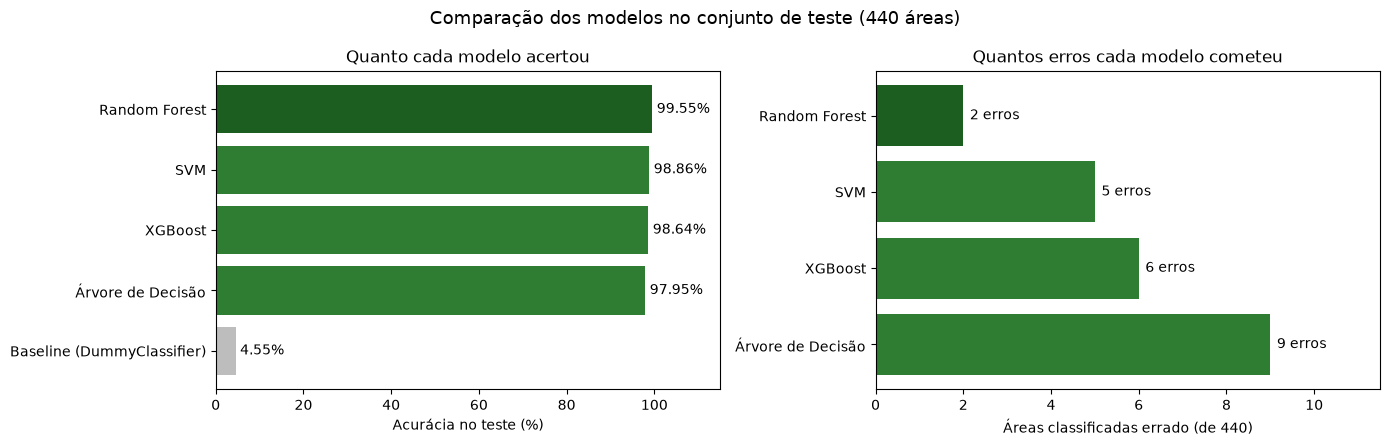

In [40]:
ordem_grafico = tabela_final.sort_values("Acurácia").index
cores_barras = ["#bdbdbd" if nome == NOME_BASELINE else COR_PRINCIPAL for nome in ordem_grafico]
cores_barras[-1] = "#1b5e20"

figura, eixos = plt.subplots(1, 2, figsize=(14, 4.5))
acuracias = tabela_final.loc[ordem_grafico, "Acurácia"] * 100
eixos[0].barh(ordem_grafico, acuracias, color=cores_barras)
for posicao, valor in enumerate(acuracias):
    eixos[0].text(valor + 1, posicao, f"{valor:.2f}%", va="center")
eixos[0].set_xlim(0, 115)
eixos[0].set_xlabel("Acurácia no teste (%)")
eixos[0].set_title("Quanto cada modelo acertou")

modelos_sem_baseline = [nome for nome in ordem_grafico if nome != NOME_BASELINE]
erros = tabela_final.loc[modelos_sem_baseline, "Erros (de 440)"]
eixos[1].barh(modelos_sem_baseline, erros, color=cores_barras[1:])
for posicao, valor in enumerate(erros):
    eixos[1].text(valor + 0.15, posicao, f"{valor} erros", va="center")
eixos[1].set_xlim(0, erros.max() + 2.5)
eixos[1].set_xlabel("Áreas classificadas errado (de 440)")
eixos[1].set_title("Quantos erros cada modelo cometeu")

figura.suptitle("Comparação dos modelos no conjunto de teste (440 áreas)", fontsize=13)
figura.tight_layout()
salvar_figura(figura, "comparacao_modelos.png")
plt.show()

F1 da validação cruzada (treino) x F1 no teste. Se forem parecidos, o modelo não decorou o treino.

In [41]:
busca_por_modelo = {
    "SVM": buscas_svm[melhor_kernel],
    "Árvore de Decisão": busca_arvore,
    "Random Forest": busca_floresta,
    "XGBoost": busca_xgboost,
}
validacao_teste = pd.DataFrame({
    "F1 validação": {nome: busca.best_score_ for nome, busca in busca_por_modelo.items()},
    "F1 teste": {nome: resultados[nome]["F1 (macro)"] for nome in NOMES_MODELOS},
})
validacao_teste["Diferença (p.p.)"] = (validacao_teste["F1 teste"] - validacao_teste["F1 validação"]) * 100
validacao_teste.round(4)

,F1 validação,F1 teste,Diferença (p.p.)
SVM,0.9857,0.9886,0.2899
Árvore de Decisão,0.9858,0.9794,-0.6372
Random Forest,0.9943,0.9955,0.1159
XGBoost,0.9920,0.9862,-0.5826


Comparação com os artigos que usaram o mesmo dataset (acurácia no teste, %). Cada artigo dividiu os dados de um jeito, então a comparação é aproximada: no nosso teste cada erro vale 0,23 ponto.

Figura salva em: Figuras\comparacao_estado_da_arte.png


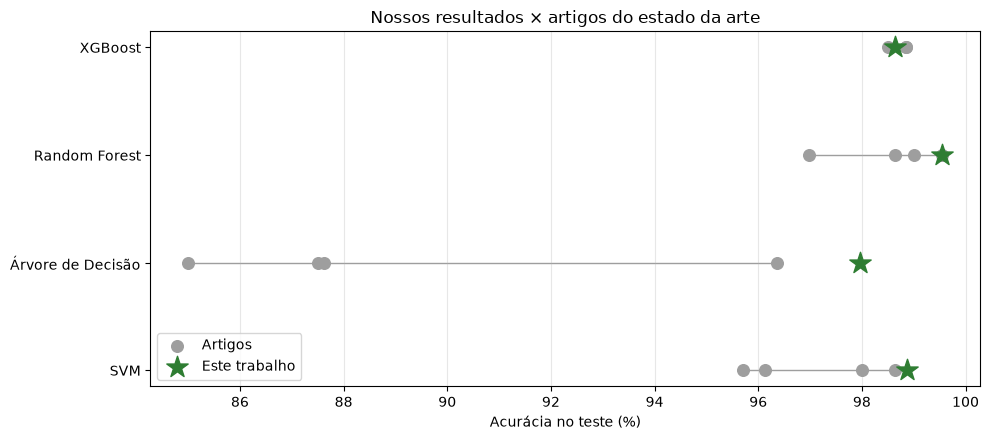

,Este trabalho,Menor artigo,Maior artigo
SVM,98.86,95.71,98.64
Árvore de Decisão,97.95,85.00,96.36
Random Forest,99.55,96.98,99.55
XGBoost,98.64,98.51,98.86


In [42]:
RESULTADOS_ARTIGOS = {
    "SVM": {"Stracqualursi (2025)": 98.64, "Ahmed et al. (2025)": 96.13, "Shastri et al. (2025)": 98.0, "Dey et al. (2024)": 95.71},
    "Árvore de Decisão": {"Stracqualursi (2025)": 96.36, "Ahmed et al. (2025)": 87.50, "Shastri et al. (2025)": 85.0, "Dey et al. (2024)": 87.62},
    "Random Forest": {"Stracqualursi (2025)": 99.55, "Ahmed et al. (2025)": 98.63, "Shastri et al. (2025)": 99.0, "Dey et al. (2024)": 96.98},
    "XGBoost": {"Stracqualursi (2025)": 98.86, "Ahmed et al. (2025)": 98.86, "Dey et al. (2024)": 98.51},
}

comparacao_artigos = pd.DataFrame({
    "Este trabalho": {nome: resultados[nome]["Acurácia"] * 100 for nome in NOMES_MODELOS},
    "Menor artigo": {nome: min(RESULTADOS_ARTIGOS[nome].values()) for nome in NOMES_MODELOS},
    "Maior artigo": {nome: max(RESULTADOS_ARTIGOS[nome].values()) for nome in NOMES_MODELOS},
})

figura, eixo = plt.subplots(figsize=(10, 4.5))
for posicao, nome in enumerate(NOMES_MODELOS):
    valores_artigos = list(RESULTADOS_ARTIGOS[nome].values())
    eixo.scatter(valores_artigos, [posicao] * len(valores_artigos), s=70, color="#9e9e9e",
                 label="Artigos" if posicao == 0 else None, zorder=2)
    eixo.hlines(posicao, min(valores_artigos), max(valores_artigos), color="#9e9e9e", linewidth=1, zorder=1)
    eixo.scatter(resultados[nome]["Acurácia"] * 100, posicao, s=260, marker="*", color=COR_PRINCIPAL,
                 label="Este trabalho" if posicao == 0 else None, zorder=3)
eixo.set_yticks(range(len(NOMES_MODELOS)), NOMES_MODELOS)
eixo.set_xlabel("Acurácia no teste (%)")
eixo.set_title("Nossos resultados × artigos do estado da arte")
eixo.legend(loc="lower left")
eixo.grid(axis="x", alpha=0.3)
figura.tight_layout()
salvar_figura(figura, "comparacao_estado_da_arte.png")
plt.show()
comparacao_artigos.round(2)

Erros mais comuns somando os quatro modelos:

In [43]:
linhas_erros = []
for nome in NOMES_MODELOS:
    errados = y_teste != previsoes_por_modelo[nome]
    for verdadeira, prevista in zip(y_teste[errados], previsoes_por_modelo[nome][errados]):
        linhas_erros.append({"Cultura verdadeira": NOMES_CULTURAS[verdadeira],
                             "Prevista como": NOMES_CULTURAS[prevista], "Modelo": nome})
erros_modelos = pd.DataFrame(linhas_erros)

erros_comuns = (erros_modelos.groupby(["Cultura verdadeira", "Prevista como"])
                .agg(**{"Erros": ("Modelo", "size"),
                        "Modelos": ("Modelo", lambda modelos: ", ".join(sorted(set(modelos))))})
                .sort_values("Erros", ascending=False)
                .reset_index())
erros_comuns.head(8)

,Cultura verdadeira,Prevista como,Erros,Modelos
0,arroz,juta,7,"Random Forest, SVM, XGBoost, Árvore de Decisão"
1,lentilha,feijão-mariposa,3,"XGBoost, Árvore de Decisão"
2,lentilha,feijão-mungo,2,XGBoost
3,feijão-mariposa,lentilha,2,"SVM, Árvore de Decisão"
4,feijão-preto (urad),milho,2,"Random Forest, Árvore de Decisão"
5,feijão-preto (urad),lentilha,2,Árvore de Decisão
6,feijão-guandu,feijão-preto (urad),1,XGBoost
7,feijão-preto (urad),feijão-mariposa,1,Árvore de Decisão


In [44]:
# arroz x juta: medianas das duas culturas
dados[dados[COLUNA_ALVO].isin(["rice", "jute"])].groupby(COLUNA_ALVO)[COLUNAS_ATRIBUTOS].median().round(1)

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
jute,78.0,46.0,40.0,25.0,79.5,6.7,175.6
rice,80.0,47.0,40.0,23.7,82.2,6.4,233.1


Arroz e juta só se diferenciam bem pela chuva, por isso é o erro mais comum.

Importância das variáveis no Random Forest: por impureza (`feature_importances_`) e por permutação (quanto o F1 cai no teste ao embaralhar a variável).

Figura salva em: Figuras\importancia_atributos.png


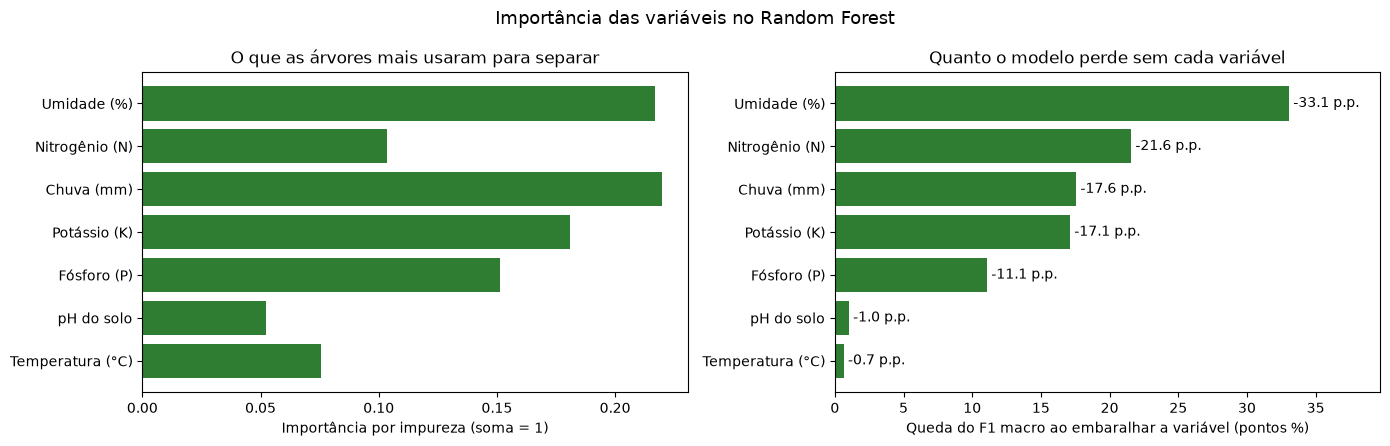

,Impureza,Permutação (queda do F1)
Umidade (%),0.217,0.331
Nitrogênio (N),0.103,0.216
Chuva (mm),0.220,0.176
Potássio (K),0.181,0.171
Fósforo (P),0.151,0.111
pH do solo,0.052,0.010
Temperatura (°C),0.075,0.007


In [45]:
from sklearn.inspection import permutation_importance

resultado_permutacao = permutation_importance(
    modelo_floresta, X_teste, y_teste, scoring="f1_macro", n_repeats=8, random_state=RANDOM_STATE)

importancias = pd.DataFrame({
    "Impureza": modelo_floresta.feature_importances_,
    "Permutação (queda do F1)": resultado_permutacao.importances_mean,
}, index=rotulos).sort_values("Permutação (queda do F1)", ascending=False)

figura, eixos = plt.subplots(1, 2, figsize=(14, 4.5))
ordem_variaveis = importancias.index[::-1]
eixos[0].barh(ordem_variaveis, importancias.loc[ordem_variaveis, "Impureza"], color=COR_PRINCIPAL)
eixos[0].set_xlabel("Importância por impureza (soma = 1)")
eixos[0].set_title("O que as árvores mais usaram para separar")

queda_f1 = importancias.loc[ordem_variaveis, "Permutação (queda do F1)"] * 100
eixos[1].barh(ordem_variaveis, queda_f1, color=COR_PRINCIPAL)
for posicao, valor in enumerate(queda_f1):
    eixos[1].text(valor + 0.3, posicao, f"-{valor:.1f} p.p.", va="center")
eixos[1].set_xlim(0, queda_f1.max() * 1.2)
eixos[1].set_xlabel("Queda do F1 macro ao embaralhar a variável (pontos %)")
eixos[1].set_title("Quanto o modelo perde sem cada variável")

figura.suptitle("Importância das variáveis no Random Forest", fontsize=13)
figura.tight_layout()
salvar_figura(figura, "importancia_atributos.png")
plt.show()
importancias.round(3)

O Random Forest foi o melhor modelo (2 erros em 440). O SVM fica muito perto e treina bem mais rápido, e a Árvore de Decisão é a mais fácil de explicar, porque as regras podem ser lidas. Umidade, nitrogênio e chuva são as variáveis que mais pesam.

## 10. Zonas do K-means + modelo supervisionado (duas etapas)

Ideia da pré-classificação vista na aula: primeiro o K-means diz em qual zona a área está, depois um modelo treinado só com as áreas daquela zona escolhe a cultura. Antes disso, uma árvore de decisão para descrever as zonas com regras simples.

In [46]:
# alvo desta árvore: a zona de cada área (não a cultura)
zona_por_area = pd.Series(grupos, index=dados.index)
zona_treino_etapa8 = zona_por_area.loc[X_treino.index]
zona_teste_etapa8 = zona_por_area.loc[X_teste.index]

PROFUNDIDADES_ZONAS = [2, 3, 4, 5, 6, None]
linhas_arvore_zonas = []
for profundidade in PROFUNDIDADES_ZONAS:
    candidata = DecisionTreeClassifier(max_depth=profundidade, random_state=RANDOM_STATE)
    nota = cross_val_score(candidata, X_treino, zona_treino_etapa8, cv=VALIDACAO_CRUZADA, scoring="f1_macro").mean()
    candidata.fit(X_treino, zona_treino_etapa8)
    linhas_arvore_zonas.append({"max_depth": "sem limite" if profundidade is None else profundidade,
                                "Folhas": candidata.get_n_leaves(), "F1 macro (validação)": nota})
tabela_arvore_zonas = pd.DataFrame(linhas_arvore_zonas)
tabela_arvore_zonas["Ganho ao aprofundar"] = tabela_arvore_zonas["F1 macro (validação)"].diff().shift(-1)

# para na primeira profundidade em que o próximo nível ganha menos de 2 pontos
posicao_escolhida = int((tabela_arvore_zonas["Ganho ao aprofundar"] < 0.02).idxmax())
profundidade_zonas = PROFUNDIDADES_ZONAS[posicao_escolhida]
print("Profundidade escolhida:", profundidade_zonas)
tabela_arvore_zonas.round(4)

Profundidade escolhida: 5


,max_depth,Folhas,F1 macro (validação),Ganho ao aprofundar
0,2,4,0.4805,0.2283
1,3,7,0.7088,0.1534
2,4,12,0.8623,0.0868
3,5,16,0.9490,0.0106
4,6,22,0.9596,0.0100
5,sem limite,43,0.9696,NaN


In [47]:
arvore_zonas = DecisionTreeClassifier(max_depth=profundidade_zonas, random_state=RANDOM_STATE)
arvore_zonas.fit(X_treino, zona_treino_etapa8)
zonas_previstas_teste = arvore_zonas.predict(X_teste)
print(f"Folhas: {arvore_zonas.get_n_leaves()} | acerto da zona no teste: "
      f"{accuracy_score(zona_teste_etapa8, zonas_previstas_teste):.1%}\n")

regras_zonas = export_text(arvore_zonas, feature_names=COLUNAS_ATRIBUTOS)
for g in LISTA_GRUPOS:
    regras_zonas = regras_zonas.replace(f"class: {g}\n", f"zona {g} · {NOMES_ZONAS[g]}\n")
print(regras_zonas)

Folhas: 16 | acerto da zona no teste: 94.1%

|--- N <= 59.50
|   |--- P <= 30.50
|   |   |--- humidity <= 69.97
|   |   |   |--- ph <= 6.57
|   |   |   |   |--- zona 5 · Quente, de solo ácido
|   |   |   |--- ph >  6.57
|   |   |   |   |--- zona 1 · Seca, de solo neutro
|   |   |--- humidity >  69.97
|   |   |   |--- temperature <= 32.56
|   |   |   |   |--- temperature <= 30.27
|   |   |   |   |   |--- zona 6 · Úmida, pobre em fósforo
|   |   |   |   |--- temperature >  30.27
|   |   |   |   |   |--- zona 6 · Úmida, pobre em fósforo
|   |   |   |--- temperature >  32.56
|   |   |   |   |--- ph <= 6.84
|   |   |   |   |   |--- zona 6 · Úmida, pobre em fósforo
|   |   |   |   |--- ph >  6.84
|   |   |   |   |   |--- zona 1 · Seca, de solo neutro
|   |--- P >  30.50
|   |   |--- P <= 100.00
|   |   |   |--- humidity <= 27.98
|   |   |   |   |--- zona 4 · Ar seco e frio
|   |   |   |--- humidity >  27.98
|   |   |   |   |--- ph <= 6.13
|   |   |   |   |   |--- zona 5 · Quente, de solo áci

**Etapa 1:** o K-means é refeito só com as áreas de treino (mesma configuração), e as áreas de teste recebem a zona do centro mais próximo. Cada grupo novo fica com o número da zona da seção 8 mais comum entre as suas áreas.

**Etapa 2:** um Random Forest e uma Árvore de Decisão por zona, com os mesmos hiperparâmetros das seções 6 e 7.

In [48]:
preparacao_treino = criar_preparacao()
kmeans_treino = KMeans(n_clusters=k_escolhido, init="k-means++", n_init=20, random_state=RANDOM_STATE)
rotulos_treino = kmeans_treino.fit_predict(preparacao_treino.fit_transform(X_treino))

mapa_zonas_treino = pd.crosstab(rotulos_treino, zona_treino_etapa8.to_numpy()).idxmax(axis=1).to_dict()
assert len(set(mapa_zonas_treino.values())) == k_escolhido


def zona_do_kmeans_treino(X_areas):
    rotulos = kmeans_treino.predict(preparacao_treino.transform(X_areas))
    return pd.Series(rotulos, index=X_areas.index).map(mapa_zonas_treino)


zona_treino = zona_do_kmeans_treino(X_treino)
zona_teste = zona_do_kmeans_treino(X_teste)
print(f"ARI com as zonas da seção 8: {adjusted_rand_score(grupos, zona_do_kmeans_treino(X_agrupamento)):.3f}")
print(f"Áreas de teste na mesma zona: {(zona_teste == zona_teste_etapa8).mean():.1%}")

# se a cultura da área não existe no treino da zona, o modelo da zona não tem como acertar
culturas_da_zona = {z: set(y_treino[zona_treino == z]) for z in LISTA_GRUPOS}
cultura_disponivel = pd.Series([y_teste[i] in culturas_da_zona[zona_teste[i]] for i in X_teste.index], index=X_teste.index)
print(f"Áreas de teste sem chance de acerto: {(~cultura_disponivel).sum()} de {len(X_teste)}")

ARI com as zonas da seção 8: 0.995
Áreas de teste na mesma zona: 100.0%
Áreas de teste sem chance de acerto: 1 de 440


In [49]:
def recomendar_em_duas_etapas(criar_modelo):
    previsoes = pd.Series(index=X_teste.index, dtype=object)
    modelos_por_zona = {}
    for zona in LISTA_GRUPOS:
        no_treino = zona_treino == zona
        modelos_por_zona[zona] = criar_modelo().fit(X_treino[no_treino], y_treino[no_treino])
        no_teste = zona_teste == zona
        if no_teste.any():
            previsoes[no_teste] = modelos_por_zona[zona].predict(X_teste[no_teste])
    return previsoes, modelos_por_zona


CONFIG_DUAS_ETAPAS = {
    "Random Forest": (RandomForestClassifier, busca_floresta.best_params_),
    "Árvore de Decisão": (DecisionTreeClassifier, busca_arvore.best_params_),
}
previsoes_duas_etapas, modelos_duas_etapas = {}, {}
for nome, (classe_modelo, parametros) in CONFIG_DUAS_ETAPAS.items():
    previsoes_duas_etapas[nome], modelos_duas_etapas[nome] = recomendar_em_duas_etapas(
        lambda: classe_modelo(**parametros, random_state=RANDOM_STATE))

linhas_comparacao = []
for nome in CONFIG_DUAS_ETAPAS:
    for abordagem, previstas in [("Modelo único (etapas 6 e 7)", previsoes_por_modelo[nome]),
                                 ("Duas etapas (zona → cultura)", previsoes_duas_etapas[nome])]:
        previstas = np.asarray(previstas)
        linhas_comparacao.append({
            "Modelo": nome, "Abordagem": abordagem,
            "Acurácia": accuracy_score(y_teste, previstas),
            "F1 (macro)": f1_score(y_teste, previstas, average="macro", zero_division=0),
            "Erros (de 440)": int((previstas != y_teste.to_numpy()).sum()),
        })
comparacao_duas_etapas = pd.DataFrame(linhas_comparacao)
comparacao_duas_etapas.round(4)

,Modelo,Abordagem,Acurácia,F1 (macro),Erros (de 440)
0,Random Forest,Modelo único (etapas 6 e 7),0.9955,0.9955,2
1,Random Forest,Duas etapas (zona → cultura),0.9886,0.9886,5
2,Árvore de Decisão,Modelo único (etapas 6 e 7),0.9795,0.9794,9
3,Árvore de Decisão,Duas etapas (zona → cultura),0.9705,0.9706,13


In [50]:
arvores_por_zona = modelos_duas_etapas["Árvore de Decisão"]
tamanho_por_zona = pd.DataFrame({
    "Zona": [NOMES_ZONAS[z] for z in LISTA_GRUPOS],
    "Áreas de treino": [int((zona_treino == z).sum()) for z in LISTA_GRUPOS],
    "Culturas na zona": [len(culturas_da_zona[z]) for z in LISTA_GRUPOS],
    "Folhas da árvore": [arvores_por_zona[z].get_n_leaves() for z in LISTA_GRUPOS],
    "Áreas de teste": [int((zona_teste == z).sum()) for z in LISTA_GRUPOS],
    "Erros RF": [int((previsoes_duas_etapas["Random Forest"][zona_teste == z] != y_teste[zona_teste == z]).sum()) for z in LISTA_GRUPOS],
    "Erros Árvore": [int((previsoes_duas_etapas["Árvore de Decisão"][zona_teste == z] != y_teste[zona_teste == z]).sum()) for z in LISTA_GRUPOS],
}, index=pd.Index(LISTA_GRUPOS, name="zona"))
print("Árvore única:", modelo_arvore.get_n_leaves(), "folhas | árvores por zona:",
      tamanho_por_zona["Folhas da árvore"].min(), "a", tamanho_por_zona["Folhas da árvore"].max(), "folhas")

for nome, previstas in previsoes_duas_etapas.items():
    errou = previstas != y_teste
    print(f"{nome}: {int(errou.sum())} erros ({int((errou & ~cultura_disponivel).sum())} na etapa 1, "
          f"{int((errou & cultura_disponivel).sum())} na etapa 2)")
tamanho_por_zona

Árvore única: 37 folhas | árvores por zona: 2 a 15 folhas
Random Forest: 5 erros (1 na etapa 1, 4 na etapa 2)
Árvore de Decisão: 13 erros (1 na etapa 1, 12 na etapa 2)


,Zona,Áreas de treino,Culturas na zona,Folhas da árvore,Áreas de teste,Erros RF,Erros Árvore
zona,,,,,,,
1,"Seca, de solo neutro",348,9,15,83,0,3
2,Rica em nitrogênio,417,7,7,107,0,1
3,Solo muito rico em P e K,160,2,2,40,0,0
4,Ar seco e frio,180,5,5,43,0,0
5,"Quente, de solo ácido",155,3,4,42,0,0
6,"Úmida, pobre em fósforo",234,5,5,57,2,5
7,"Muito chuvosa, rica em N",266,5,13,68,3,4


Figura salva em: Figuras\duas_etapas_comparacao.png


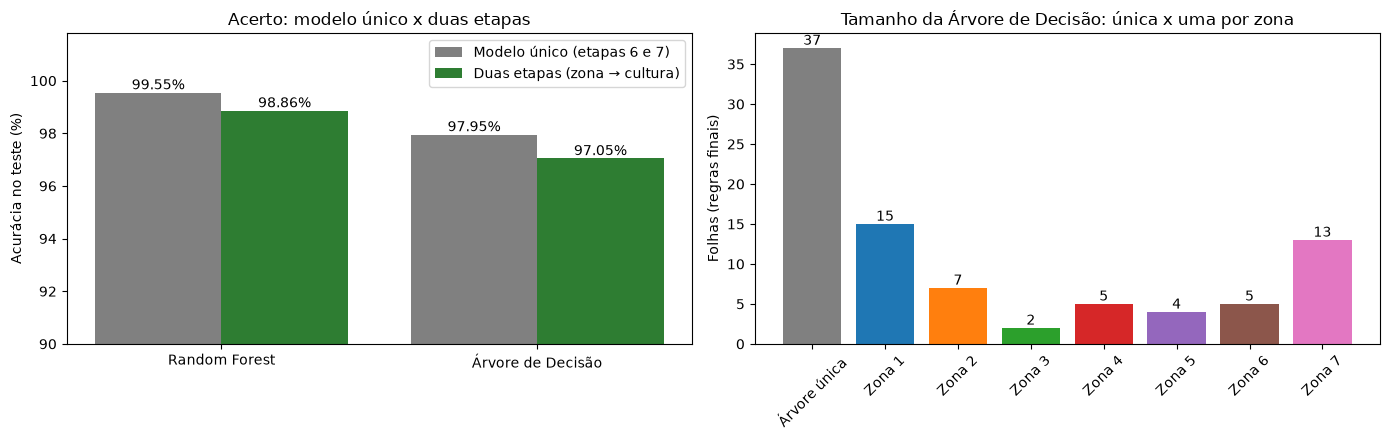

In [51]:
CORES_GRUPOS = dict(zip(LISTA_GRUPOS, plt.get_cmap("tab10").colors))

figura, eixos = plt.subplots(1, 2, figsize=(14, 4.5))
posicoes = np.arange(len(CONFIG_DUAS_ETAPAS))
for deslocamento, (abordagem, cor) in zip([-0.2, 0.2], [("Modelo único (etapas 6 e 7)", "gray"),
                                                        ("Duas etapas (zona → cultura)", COR_PRINCIPAL)]):
    valores = comparacao_duas_etapas[comparacao_duas_etapas["Abordagem"] == abordagem]["Acurácia"] * 100
    barras = eixos[0].bar(posicoes + deslocamento, valores, width=0.4, color=cor, label=abordagem)
    eixos[0].bar_label(barras, fmt="%.2f%%")
eixos[0].set_xticks(posicoes, list(CONFIG_DUAS_ETAPAS))
eixos[0].set_ylim(90, 101.8)
eixos[0].set_ylabel("Acurácia no teste (%)")
eixos[0].set_title("Acerto: modelo único x duas etapas")
eixos[0].legend(loc="upper right")

rotulos_barras = ["Árvore única"] + [f"Zona {z}" for z in LISTA_GRUPOS]
folhas = [modelo_arvore.get_n_leaves()] + list(tamanho_por_zona["Folhas da árvore"])
barras = eixos[1].bar(rotulos_barras, folhas, color=["gray"] + [CORES_GRUPOS[z] for z in LISTA_GRUPOS])
eixos[1].bar_label(barras)
eixos[1].set_ylabel("Folhas (regras finais)")
eixos[1].set_title("Tamanho da Árvore de Decisão: única x uma por zona")
eixos[1].tick_params(axis="x", rotation=45)
figura.tight_layout()
salvar_figura(figura, "duas_etapas_comparacao.png")
plt.show()

As duas etapas não melhoraram o acerto: cada modelo de zona treina com bem menos áreas, e o modelo único já separava bem as 22 culturas. O ganho é na explicação, porque na maioria das zonas a árvore fica bem menor.

Por último, olhamos se os erros dos modelos únicos acontecem entre culturas da mesma zona:

In [52]:
zona_principal_cultura = percentual_culturas.idxmax(axis=1)

erros_por_zona = []
for nome in NOMES_MODELOS:
    previstas = pd.Series(previsoes_por_modelo[nome], index=y_teste.index)
    for indice in y_teste.index[previstas != y_teste]:
        erros_por_zona.append({
            "Modelo": nome,
            "Cultura real": NOMES_CULTURAS[y_teste[indice]],
            "Prevista": NOMES_CULTURAS[previstas[indice]],
            "Zona da área": zona_teste_etapa8[indice],
            "Prevista é da mesma zona": zona_principal_cultura[previstas[indice]] == zona_teste_etapa8[indice],
        })
erros_por_zona = pd.DataFrame(erros_por_zona)

mesma_zona = int(erros_por_zona["Prevista é da mesma zona"].sum())
print(f"Erros dos 4 modelos: {len(erros_por_zona)} | na mesma zona: {mesma_zona} ({mesma_zona / len(erros_por_zona):.0%})\n")
print(pd.crosstab(erros_por_zona["Modelo"], erros_por_zona["Zona da área"].map(lambda z: f"G{z}")))

tabela_arvore_zonas.to_csv(os.path.join(PASTA_RESULTADOS, "arvore_zonas_profundidade.csv"), index=False)
comparacao_duas_etapas.to_csv(os.path.join(PASTA_RESULTADOS, "duas_etapas_comparacao.csv"), index=False)
tamanho_por_zona.to_csv(os.path.join(PASTA_RESULTADOS, "duas_etapas_por_zona.csv"))
erros_por_zona.to_csv(os.path.join(PASTA_RESULTADOS, "erros_por_zona.csv"), index=False)

Erros dos 4 modelos: 22 | na mesma zona: 17 (77%)

Zona da área       G1  G2  G5  G7
Modelo                           
Random Forest       1   0   0   1
SVM                 0   1   1   3
XGBoost             3   0   1   2
Árvore de Decisão   6   0   1   2


A maior parte dos erros é troca entre culturas da mesma zona (por exemplo arroz e juta na zona 7), ou seja, os modelos erram justamente entre as culturas que o K-means já tinha colocado juntas.

## 11. Salvar os modelos para a página web

Os quatro modelos são salvos com `joblib` para a página da pasta `app/` usar exatamente os mesmos modelos avaliados aqui. Para abrir: `python app/app.py` e acessar http://127.0.0.1:5000.

In [53]:
import joblib

PASTA_MODELOS = "Modelos"
CAMINHO_MODELOS = os.path.join(PASTA_MODELOS, "modelos_recomendacao.joblib")
os.makedirs(PASTA_MODELOS, exist_ok=True)

modelos_finais = {
    "Random Forest": modelo_floresta,
    "SVM": modelo_svm,
    "XGBoost": modelo_xgboost,
    "Árvore de Decisão": modelo_arvore,
}
pacote_modelos = {
    "modelos": modelos_finais,
    "codificador_alvo": codificador_alvo,
    "colunas_atributos": COLUNAS_ATRIBUTOS,
    "nomes_culturas": NOMES_CULTURAS,
    "metricas_teste": {
        nome: {"acuracia": resultados[nome]["Acurácia"], "f1_macro": resultados[nome]["F1 (macro)"]}
        for nome in modelos_finais
    },
    "hiperparametros": {
        "Random Forest": busca_floresta.best_params_,
        "SVM": {"kernel": melhor_kernel, **buscas_svm[melhor_kernel].best_params_},
        "XGBoost": busca_xgboost.best_params_,
        "Árvore de Decisão": busca_arvore.best_params_,
    },
    "limites_atributos": dados[COLUNAS_ATRIBUTOS].agg(["min", "median", "max"]).to_dict(),
    "perfil_culturas": dados.groupby(COLUNA_ALVO)[COLUNAS_ATRIBUTOS].median().to_dict(orient="index"),
}
joblib.dump(pacote_modelos, CAMINHO_MODELOS)

# confere se os modelos recarregados dão o mesmo resultado
pacote_recarregado = joblib.load(CAMINHO_MODELOS)
for nome, modelo in pacote_recarregado["modelos"].items():
    previstas = modelo.predict(X_teste)
    if nome == "XGBoost":
        previstas = codificador_alvo.inverse_transform(previstas)
    print(f"{nome:<18} {accuracy_score(y_teste, previstas):.4f}")

Random Forest      0.9955


SVM                0.9886
XGBoost            0.9864
Árvore de Decisão  0.9795
